    Ce travail est realisee par Yasmine Frikha et Nada Rekik 
    2BD2


    ***Analyse du dataset-bad_hospital_dataset.csv-***

1ere partie


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Importater des bibliothèques
On importe les bibliothèques:
- pandas: manipulation et analyse des données tabulaires
- numpy : calculs numériques et gestion des tableaux
- matplotlib / seaborn: création de graphiques et visualisations statistiques

In [2]:
df = pd.read_csv(r"C:\Users\User\Downloads\bad_hospital_dataset.csv")


On charge le fichier CSV dans un DataFrame pandas. Ce dataset hospitalier a été volontairement dégradé
à l'aide de ChatGPT en introduisant des valeurs manquantes, des erreurs textuelles (`"error"`) et des
doublons, afin de simuler des données réelles brutes telles qu'on les trouve en pratique.

In [3]:
display(df.head())
df.tail(14)

,patient_id,admission_date,season,age,gender,region,primary_diagnosis,comorbidities_count,length_of_stay,treatment_type,medications_count,followup_visits_last_year,prev_readmissions,insurance_type,discharge_disposition,readmission_risk_score,label
0,P00787,2022-02-26,Winter,NaN,Female,West,NaN,7.0,10.0,Medical,10.0,7.0,error,NaN,Skilled Nursing,0.97,1.0
1,P06822,2023-03-03,Spring,89.0,NaN,East,NaN,9.0,error,NaN,14.0,error,3.0,Medicare,NaN,0.97,NaN
2,NaN,NaN,Winter,NaN,NaN,East,Heart Failure,NaN,10.0,NaN,NaN,6.0,2.0,Medicare,Skilled Nursing,NaN,0.0
3,P03206,2021-05-08,Spring,error,Male,East,Stroke,NaN,NaN,Medical,6.0,error,NaN,Private,NaN,0.85,1.0
4,P00244,2021-12-25,Winter,error,Female,East,COPD,5.0,NaN,Surgical,NaN,4.0,error,Medicare,Home Health,0.97,1.0


,patient_id,admission_date,season,age,gender,region,primary_diagnosis,comorbidities_count,length_of_stay,treatment_type,medications_count,followup_visits_last_year,prev_readmissions,insurance_type,discharge_disposition,readmission_risk_score,label
8786,P00148,2022-09-26,NaN,NaN,NaN,NaN,Diabetes,error,6.0,NaN,5.0,2.0,0.0,Private,Home Health,0.18,error
8787,P06501,2022-05-19,NaN,78.0,Female,North,Diabetes,NaN,6.0,Medical,10.0,5.0,2.0,Medicare,Home Health,0.97,NaN
8788,NaN,2023-11-23,Fall,39.0,Female,North,Stroke,6.0,10.0,Medical,9.0,3.0,error,Private,Skilled Nursing,0.97,1.0
8789,P05029,2022-07-10,NaN,79.0,Female,NaN,Appendicitis,5.0,8.0,Surgical,8.0,4.0,error,Medicare,Home Health,0.97,1.0
8790,P04809,2021-12-02,NaN,82.0,Male,South,COPD,7.0,9.0,Conservative,10.0,7.0,error,Medicare,NaN,0.97,1.0
8791,NaN,2022-09-20,NaN,43.0,Male,East,Kidney Disease,3.0,6.0,Interventional,4.0,2.0,1.0,Private,Home Health,NaN,NaN
8792,NaN,2023-12-03,Winter,NaN,Female,East,Hypertension,3.0,7.0,Medical,NaN,NaN,2.0,Medicaid,Home Health,0.72,0.0
8793,P04872,2021-04-07,Spring,error,Male,East,Kidney Disease,5.0,NaN,Conservative,10.0,5.0,2.0,Medicare,Home Health,0.97,1.0
8794,P01889,2022-01-22,Winter,49.0,Male,South,Heart Failure,3.0,8.0,Surgical,4.0,2.0,1.0,Private,Home Health,0.67,1.0
8795,P03334,2022-01-12,Winter,67.0,NaN,Central,Hypertension,4.0,7.0,Medical,NaN,6.0,3.0,Medicare,NaN,0.97,1.0



`df.head()` affiche les 5 premières lignes afin  de comprendre la structure du dataset.
`df.tail(14)` affiche les 14 derniere lignes .
Le dataset contient 17 colonnes :
- patient_id : identifiant unique du patient
- admission_date : date d'entrée à l'hôpital
- season : saison d'admission
- age : âge du patient
- gender : sexe du patient
- region : région 
- primary_diagnosis : diagnostic principal
- comorbidities_count : nombre de maladies ..
- length_of_stay : durée du séjour hospitalier (en jours)
- treatment_type : type de traitement 
- medications_count : nombre de médicaments prescrits
- followup_visits_last_year : nombre de visites de suivi l'année précédente
- prev_readmissions : nombre de réadmissions antérieures
- insurance_type : type d'assurance médicale
- discharge_disposition : lieu de sortie du patient
- readmission_risk_score : score de risque de réadmission
- label : variable cible (1 = réadmis, 0 = non réadmis)

 Dimensions 
`df.shape` retourne le nombre de lignes et de colonnes. Cela donne une première idée de la
taille du dataset.

In [4]:
print(df.shape)

(8800, 17)


Résultat :Le dataset contient 8 800 lignes × 17 colonnes.
Il s'agit d'un dataset de taille moyenne, suffisant pour des analyses .

Types des variables
`df.dtypes` affiche le type de chaque colonne.

In [5]:
print(df.dtypes)

patient_id                   object
admission_date               object
season                       object
age                          object
gender                       object
region                       object
primary_diagnosis            object
comorbidities_count          object
length_of_stay               object
treatment_type               object
medications_count            object
followup_visits_last_year    object
prev_readmissions            object
insurance_type               object
discharge_disposition        object
readmission_risk_score       object
label                        object
dtype: object


Résultat :Toutes les colonnes sont de type object (texte), y compris age, length_of_stay, medications_count...


`df.info()` fournit un résumé complet : types, nombre de valeurs non-nulles, et utilisation mémoire.

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8800 entries, 0 to 8799
Data columns (total 17 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   patient_id                 7037 non-null   object
 1   admission_date             7036 non-null   object
 2   season                     7040 non-null   object
 3   age                        7225 non-null   object
 4   gender                     7028 non-null   object
 5   region                     7041 non-null   object
 6   primary_diagnosis          7037 non-null   object
 7   comorbidities_count        7226 non-null   object
 8   length_of_stay             7208 non-null   object
 9   treatment_type             7039 non-null   object
 10  medications_count          7201 non-null   object
 11  followup_visits_last_year  7223 non-null   object
 12  prev_readmissions          7229 non-null   object
 13  insurance_type             7042 non-null   object
 14  discharg

Résultat :On confirme les 8 800 lignes et 17 colonnes. La présence de valeurs non-nulles
inférieures à 8 800 dans chaque colonne révèle des 
valeurs manquantes (NaN), entre 1 571 et 1 763 par colonne,
soit environ .

2eme partie 

In [7]:
error_counts = (df == "error").sum().sort_values(ascending=False)
print(f"Nombre total de 'error' dans le dataset : {error_counts.sum()}")

Nombre total de 'error' dans le dataset : 7040


In [8]:
na_counts = df.isna().sum().sort_values(ascending=False)
display(pd.DataFrame({
    "error_count": error_counts,
    "na_count": na_counts
}).sort_values(by=["error_count", "na_count"], ascending=False))

,error_count,na_count
readmission_risk_score,880,1611
medications_count,880,1599
length_of_stay,880,1592
label,880,1589
followup_visits_last_year,880,1577
age,880,1575
comorbidities_count,880,1574
prev_readmissions,880,1571
discharge_disposition,0,1778
gender,0,1772


On affiche un tableau combinant le nombre d'erreurs et de NaN par colonne pour avoir une vue d'ensemble.

 On identifie **7 040 valeurs `"error"`** réparties sur plusieurs colonnes,
notamment followup_visits_last_year, label et age. D'autres colonnes (gender, admission_date)
ne contiennent que des NaN, sans erreurs textuelles.

In [9]:
(df.isna().sum().sort_values(ascending=False))

discharge_disposition        1778
gender                       1772
admission_date               1764
patient_id                   1763
primary_diagnosis            1763
treatment_type               1761
season                       1760
region                       1759
insurance_type               1758
readmission_risk_score       1611
medications_count            1599
length_of_stay               1592
label                        1589
followup_visits_last_year    1577
age                          1575
comorbidities_count          1574
prev_readmissions            1571
dtype: int64

**Résultat :** Toutes les colonnes contiennent des NaN, avec un nombre variant entre
**1 571 et 1 778**. Aucune colonne n'est exempte de données manquantes.

On remplace toutes les occurrences de `"error"` par `NaN` avec `df.replace()`.

In [10]:
# Remplacer "error" par NaN partout
df = df.replace("error", np.nan)


On vérifie qu'il ne reste aucune valeur `"error"` dans le dataset.

In [11]:
error_counts = (df == "error").sum().sort_values(ascending=False)
print(f"Nombre total de 'error' dans le dataset : {error_counts.sum()}")

Nombre total de 'error' dans le dataset : 0


 Le comptage retourne **0**, confirmant l'efficacité totale du remplacement.


On recalcule le total de NaN. Les colonnes les plus affectées après remplacement sont :
- readmission_risk_score : **2 491 NaN**
- medications_count : **2 479 NaN**
- length_of_stay : **2 472 NaN**



In [12]:
na_counts = df.isna().sum().sort_values(ascending=False)
print(f"Total de valeurs manquantes dans le dataset : {na_counts.sum()}")

display(pd.DataFrame({
    "error_count": error_counts,
    "na_count": na_counts
}).sort_values(by=["error_count", "na_count"], ascending=False))

Total de valeurs manquantes dans le dataset : 35606


,error_count,na_count
readmission_risk_score,0,2491
medications_count,0,2479
length_of_stay,0,2472
label,0,2469
followup_visits_last_year,0,2457
age,0,2455
comorbidities_count,0,2454
prev_readmissions,0,2451
discharge_disposition,0,1778
gender,0,1772


On examine la distribution de chaque colonne clé pour comprendre les données avant nettoyage final.

In [13]:
df["readmission_risk_score"].value_counts(dropna=False)

readmission_risk_score
0.97    2545
NaN     2491
0.63     135
0.67     120
0.75     119
        ... 
0.31       3
0.39       3
0.38       2
0.11       2
0.34       1
Name: count, Length: 85, dtype: int64

In [14]:
df["medications_count"].value_counts(dropna=False)

medications_count
NaN     2479
8.0     1586
6.0     1379
10.0     822
7.0      694
4.0      633
9.0      386
12.0     259
3.0      168
11.0     160
5.0       88
2.0       63
14.0      47
13.0      32
15.0       2
16.0       1
17.0       1
Name: count, dtype: int64

**medications_count :** 2 479 NaN. Le nombre de médicaments le plus fréquent est
**8** (1 586 patients), suivi de 6 (1 379 patients). Les extrêmes (15-17 médicaments) sont très rares.

In [15]:
df["label"].value_counts(dropna=False)

label
1.0    4856
NaN    2469
0.0    1475
Name: count, dtype: int64

**label (variable cible) :** 4 856 réadmis (1.0), 1 475 non réadmis (0.0),
2 469 NaN. On note un fort déséquilibre des classes.

In [16]:
df["length_of_stay"].value_counts(dropna=False)

length_of_stay
NaN     2472
8.0     1166
7.0     1134
6.0     1044
9.0      996
10.0     694
5.0      608
11.0     352
4.0      140
12.0     127
13.0      44
14.0      12
3.0        9
15.0       2
Name: count, dtype: int64

**length_of_stay :** 2 472 NaN. La plupart des patients restent **8 jours**
à l'hôpital (1 166 patients). Les durées varient entre **3 et 15 jours**.

In [17]:
df["followup_visits_last_year"].value_counts(dropna=False)

followup_visits_last_year
NaN     2457
2.0     1992
4.0     1808
6.0      798
3.0      779
5.0      514
1.0      184
7.0      109
8.0      109
0.0       37
9.0        9
10.0       4
Name: count, dtype: int64

**followup_visits_last_year :** 2 457 NaN. Principalement 2 ou 4 visites.
Les visites varient de **0 à 10** par an.

In [18]:
df["age"].value_counts(dropna=False)

age
NaN     2455
54.0     164
63.0     164
57.0     164
47.0     155
        ... 
22.0      17
21.0      17
23.0      16
92.0      16
19.0       7
Name: count, Length: 79, dtype: int64

**age :** 2 455 NaN. Les âges les plus fréquents sont 54, 63 et 57 ans.
Les âges varient de **19 à 92 ans**.

In [19]:
df["comorbidities_count"].value_counts(dropna=False)

comorbidities_count
NaN     2454
4.0     1892
5.0     1530
3.0     1227
6.0      828
2.0      420
7.0      284
1.0       98
8.0       54
9.0       11
10.0       2
Name: count, dtype: int64

**comorbidities_count :** 2 454 NaN. La majorité a **4 comorbidités**
(1 892 patients) ou 5 (1 530 patients). Varie de 1 à 10.


On supprime les lignes ayant des NaN dans les colonnes essentielles à l'analyse. 

In [20]:
df = df.dropna(subset=['readmission_risk_score'])
df = df.dropna(subset=['medications_count'])
df = df.dropna(subset=['length_of_stay'])
df = df.dropna(subset=['label'])
df = df.dropna(subset=['followup_visits_last_year'])
df = df.dropna(subset=['age'])


On définit la liste complète des 16 colonnes essentielles et on supprime toutes les lignes
contenant au moins un NaN parmi elles

In [21]:
required = [
    "admission_date","season","age","gender","region","primary_diagnosis",
    "comorbidities_count","length_of_stay","treatment_type","medications_count",
    "followup_visits_last_year","prev_readmissions","insurance_type",
    "discharge_disposition","readmission_risk_score","label"
]
df = df.dropna(subset=required)

df.isna().sum().sort_values(ascending=False)

patient_id                   22
treatment_type                0
readmission_risk_score        0
discharge_disposition         0
insurance_type                0
prev_readmissions             0
followup_visits_last_year     0
medications_count             0
length_of_stay                0
admission_date                0
comorbidities_count           0
primary_diagnosis             0
region                        0
gender                        0
age                           0
season                        0
label                         0
dtype: int64

In [22]:
print(df.shape)

(110, 17)


**Résultat :** Le dataset est réduit de **8 800 à 110 lignes**. Cette forte réduction
s'explique par la combinaison de NaN dans chaque colonne : dès qu'une seule colonne est manquante
sur une ligne, cette ligne est supprimée. Le dataset final est petit mais **entièrement complet**.

In [23]:
df = df.drop(columns='patient_id')
df.head()

,admission_date,season,age,gender,region,primary_diagnosis,comorbidities_count,length_of_stay,treatment_type,medications_count,followup_visits_last_year,prev_readmissions,insurance_type,discharge_disposition,readmission_risk_score,label
34,2021-01-18,Winter,42.0,Female,Central,Heart Failure,4.0,9.0,Surgical,8.0,4.0,2.0,Private,Home Health,0.97,1.0
145,2022-06-07,Summer,59.0,Female,North,Diabetes,5.0,9.0,Medical,8.0,4.0,1.0,Medicaid,Home Health,0.71,1.0
154,2022-08-01,Summer,55.0,Male,North,Diabetes,5.0,7.0,Medical,8.0,2.0,1.0,Medicaid,Home Health,0.66,1.0
310,2021-10-15,Fall,62.0,Female,East,Kidney Disease,4.0,8.0,Medical,7.0,3.0,1.0,Private,Home Health,0.85,1.0
359,2021-01-23,Winter,62.0,Male,South,Sepsis,5.0,12.0,Surgical,8.0,2.0,1.0,Uninsured,Home Health,0.97,1.0



La colonne `patient_id` est un identifiant technique sans valeur analytique. On la supprime
pour ne conserver que les variables utiles à l'analyse.

dans cette etape ,On identifie les lignes entièrement dupliquées (même valeur sur toutes les colonnes).

In [24]:
duplicateRowsDF = df[df.duplicated()]
print("Duplicate Rows except first occurrence based on all columns are :")
duplicateRowsDF.shape

Duplicate Rows except first occurrence based on all columns are :


(4, 16)

4 lignes dupliquées détectées sur 110,.
Ces doublons correspondent à des patients dont toutes les caractéristiques sont identiques :
- Femme, 45 ans, appendicite, 4 jours, 6 médicaments — non réadmise
- Homme, 55 ans, diabète, 7 jours, 8 médicaments — réadmis
- Femme, 73 ans, diabète, 9 jours, 8 médicaments — réadmise
- Homme, 60 ans, maladie rénale, 7 jours, 7 médicaments — réadmis

In [25]:
print(duplicateRowsDF)

     admission_date  season   age  gender   region primary_diagnosis  \
3916     2021-04-06  Spring  45.0  Female    South      Appendicitis   
4847     2022-08-01  Summer  55.0    Male    North          Diabetes   
5055     2023-06-16  Summer  73.0  Female  Central          Diabetes   
7109     2023-08-24  Summer  60.0    Male    North    Kidney Disease   

     comorbidities_count length_of_stay treatment_type medications_count  \
3916                 3.0            4.0        Medical               6.0   
4847                 5.0            7.0        Medical               8.0   
5055                 5.0            9.0        Medical               8.0   
7109                 4.0            7.0   Conservative               7.0   

     followup_visits_last_year prev_readmissions insurance_type  \
3916                       2.0               1.0      Uninsured   
4847                       2.0               1.0       Medicaid   
5055                       5.0               2.0       Me

In [26]:
print("Avant :", df.shape)
df = df.drop_duplicates()
print("Après :", df.shape)

Avant : (110, 16)
Après : (106, 16)


**Résultat :** Le dataset passe de **110 à 106 lignes** après suppression des 4 doublons.
Ces 106 lignes constituent la **base finale propre** utilisée pour toutes les analyses suivantes.

3eme partie 


Toutes les colonnes numériques étant de type `object`, on les convertit avec `pd.to_numeric()`
avant de calculer les statistiques.

In [27]:
# Conversion et min/max de age
df['age'] = pd.to_numeric(df['age'], errors='coerce')
print('age — max :', df['age'].max(), '/ min :', df['age'].min())

# Conversion et min/max de medications_count
df['medications_count'] = pd.to_numeric(df['medications_count'], errors='coerce')
print('medications_count — max :', df['medications_count'].max(), '/ min :', df['medications_count'].min())

# Conversion et min/max de comorbidities_count
df['comorbidities_count'] = pd.to_numeric(df['comorbidities_count'], errors='coerce')
print('comorbidities_count — max :', df['comorbidities_count'].max(), '/ min :', df['comorbidities_count'].min())

# Conversion et min/max de length_of_stay
df['length_of_stay'] = pd.to_numeric(df['length_of_stay'], errors='coerce')
print('length_of_stay — max :', df['length_of_stay'].max(), '/ min :', df['length_of_stay'].min())

# Conversion et min/max de followup_visits_last_year
df['followup_visits_last_year'] = pd.to_numeric(df['followup_visits_last_year'], errors='coerce')
print('followup_visits_last_year — max :', df['followup_visits_last_year'].max(), '/ min :', df['followup_visits_last_year'].min())

age — max : 95.0 / min : 18.0
medications_count — max : 14.0 / min : 3.0
comorbidities_count — max : 8.0 / min : 2.0
length_of_stay — max : 13.0 / min : 4.0
followup_visits_last_year — max : 8.0 / min : 1.0


Résultats:
- age : varie  de 18 à 95 ans — couvre toutes les tranches d'adultes
- medications_count : de 3 à 14 médicaments — tous les patients reçoivent au moins 3 médicaments et au plus 14 medicaments .
- comorbidities_count : de 2 à 8 maladies — la plupart ont 4 ou 5 comorbidités
- length_of_stay : de 4 à 13 jours — séjours allant de courts à assez longs de 4 jours a 13 jours 
- followup_visits_last_year: de 1 à 8 visites .

Moyenne et médiane de la durée de séjour

In [28]:
mean_stay = df['length_of_stay'].mean()
median_stay = df['length_of_stay'].median()
print("Durée moyenne du séjour :", round(mean_stay, 2), "jours")
print("Durée médiane du séjour :", median_stay, "jours")

Durée moyenne du séjour : 7.58 jours
Durée médiane du séjour : 7.5 jours


**Résultat :** La durée moyenne est de **7,58 jours** et la médiane de **7,5 jours**.
La proximité de ces deux valeurs indique une distribution symétrique, sans déséquilibre notable
causé par des valeurs extrêmes.

Quartiles de la durée de séjour


In [29]:
print('Q1 :', df['length_of_stay'].quantile(0.25))
print('Q2 (médiane) :', df['length_of_stay'].quantile(0.5))
print('Q3 :', df['length_of_stay'].quantile(0.75))

Q1 : 6.0
Q2 (médiane) : 7.5
Q3 : 9.0


**Résultat :**
- **Q1 = 6 jours** : 25% des patients restent 6 jours ou moins
- **Q2 = 7,5 jours** : la moitié des patients restent 7,5 jours ou moins
- **Q3 = 9 jours** : 75% restent 9 jours ou moins

L'IQR = Q3 - Q1 = **3 jours**, indiquant une dispersion modérée. La majorité des séjours
se concentre entre 6 et 9 jours.

IQR de medications_count

In [30]:
Q1 = df['medications_count'].quantile(0.25)
Q3 = df['medications_count'].quantile(0.75)
IQR = Q3 - Q1

print("Q1 :", Q1)
print("Q3 :", Q3)
print("IQR :", IQR)

Q1 : 6.0
Q3 : 8.0
IQR : 2.0


**Résultat :** Q1 = 6, Q3 = 8, **IQR = 2**.
50% des patients reçoivent entre 6 et 8 médicaments. Cette faible dispersion montre
que les prescriptions sont relativement homogènes pour la majorité des patients.

Distributions des variables 

In [31]:

mean_visit = df['followup_visits_last_year'].mean()
print("Nombre moyen de visites de suivi :", round(mean_visit, 2))


print("\n--- Saison ---")
print(df['season'].value_counts())

print("\n--- Genre ---")
print(df['gender'].value_counts())

print("\n--- Label (réadmission) ---")
print(df['label'].value_counts())

print("\n--- Type de traitement ---")
print(df['treatment_type'].value_counts())

print("\n--- Type d'assurance ---")
print(df['insurance_type'].value_counts())

print("\n--- Lieu de sortie ---")
print(df['discharge_disposition'].value_counts())

Nombre moyen de visites de suivi : 3.64

--- Saison ---
season
Fall      34
Winter    30
Summer    25
Spring    17
Name: count, dtype: int64

--- Genre ---
gender
Female    55
Male      51
Name: count, dtype: int64

--- Label (réadmission) ---
label
1.0    84
0.0    22
Name: count, dtype: int64

--- Type de traitement ---
treatment_type
Surgical          36
Medical           34
Interventional    26
Conservative      10
Name: count, dtype: int64

--- Type d'assurance ---
insurance_type
Private      37
Medicare     37
Medicaid     21
Uninsured    11
Name: count, dtype: int64

--- Lieu de sortie ---
discharge_disposition
Home Health        79
Skilled Nursing    20
Home                5
Rehab               2
Name: count, dtype: int64


-Saison: L'automne est la saison la plus représentée avec 34 admissions, suivie de l'hiver (30), l'été (25) et enfin le printemps (17). Les admissions sont donc plus fréquentes en fin d'année.
-Genre:  On compte 55 femmes et 51 hommes, une répartition très proche qui montre que les deux genres sont presque également représentés dans le dataset.
-Réadmission: 84 patients ont été réadmis contre seulement 22 qui ne l'ont pas été. La majorité des patients du dataset ont donc nécessité un retour à l'hôpital après leur première sortie.
-Type de traitement: Le traitement chirurgical est le plus fréquent (36), suivi du médical (34), de l'interventionnel (26) et du conservateur (10). 
-Type d'assurance: L'assurance privée et Medicare comptent chacune 37 patients, suivies de Medicaid (21) et des non-assurés (11). La couverture assurantielle est donc présente pour la grande majorité des patients, seuls 11 n'en disposant pas.
-Lieu de sortie: La grande majorité des patients (79) sont sortis vers des soins à domicile encadrés (Home Health), 20 vers un établissement de soins spécialisés, 5 directement à domicile sans suivi particulier et seulement 2 en rééducation. La sortie vers le domicile est donc la situation la plus courante.

 Visualisations

 Histogrammes des variables catégorielles


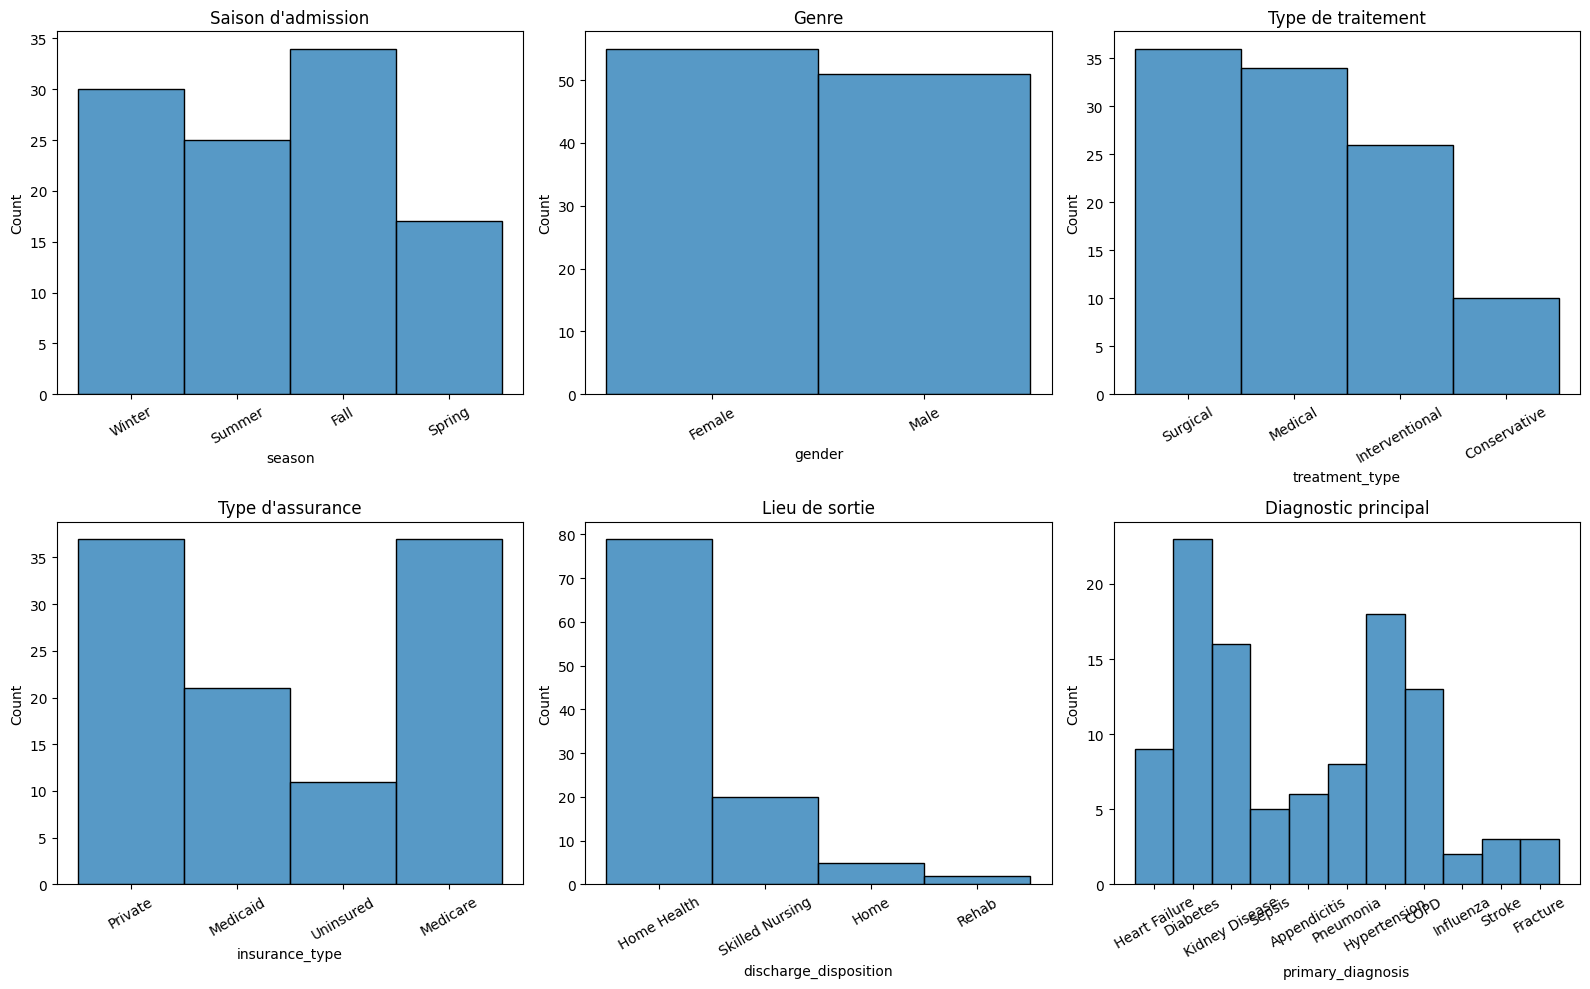

In [32]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

sns.histplot(df["season"], kde=False, ax=axes[0,0]).set_title("Saison d'admission")
sns.histplot(df["gender"], kde=False, ax=axes[0,1]).set_title("Genre")
sns.histplot(df["treatment_type"], kde=False, ax=axes[0,2]).set_title("Type de traitement")
sns.histplot(df["insurance_type"], kde=False, ax=axes[1,0]).set_title("Type d'assurance")
sns.histplot(df["discharge_disposition"], kde=False, ax=axes[1,1]).set_title("Lieu de sortie")
sns.histplot(df["primary_diagnosis"], kde=False, ax=axes[1,2]).set_title("Diagnostic principal")

for ax in axes.flatten():
    ax.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

**Interprétation :**
- **Saison** : L'automne et l'hiver concentrent le plus d'admissions, probablement à cause
  des maladies respiratoires et virales plus fréquentes en saison froide.
- **Genre** : Répartition quasi-équilibrée, sans biais de genre significatif.
- **Traitement** : La chirurgie et le traitement médical dominent, indiquant des cas cliniques souvent sérieux.
- **Assurance** : La majorité des patients est bien couverte (privée + Medicare = 70%).
- **Sortie** : La grande majorité rentre à domicile avec suivi, signe d'un bon rétablissement général.

 Histogrammes des variables numériques

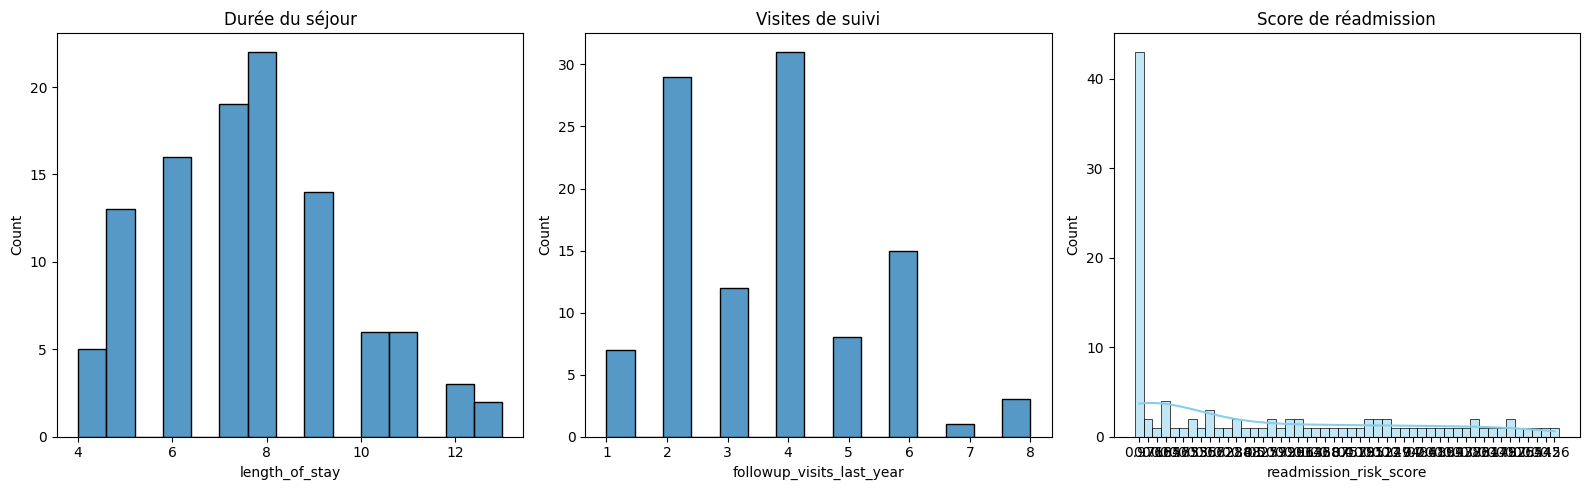

In [33]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.histplot(df['length_of_stay'], kde=False, bins=15, ax=axes[0]).set_title("Durée du séjour")
sns.histplot(df['followup_visits_last_year'], kde=False, bins=15, ax=axes[1]).set_title("Visites de suivi")
sns.histplot(df['readmission_risk_score'], kde=True, bins=30, color='skyblue', ax=axes[2]).set_title("Score de réadmission")

plt.tight_layout()
plt.show()


- **Durée de séjour** : Pic à 8 jours (22 patients). La majorité séjourne entre 6 et 10 jours.
- **Visites de suivi** : Distribution assez uniforme entre 1 et 8 visites/an.
- **Score de réadmission** : La courbe de densité montre la distribution du risque parmi les patients.

### 4.3 Courbes de densité 

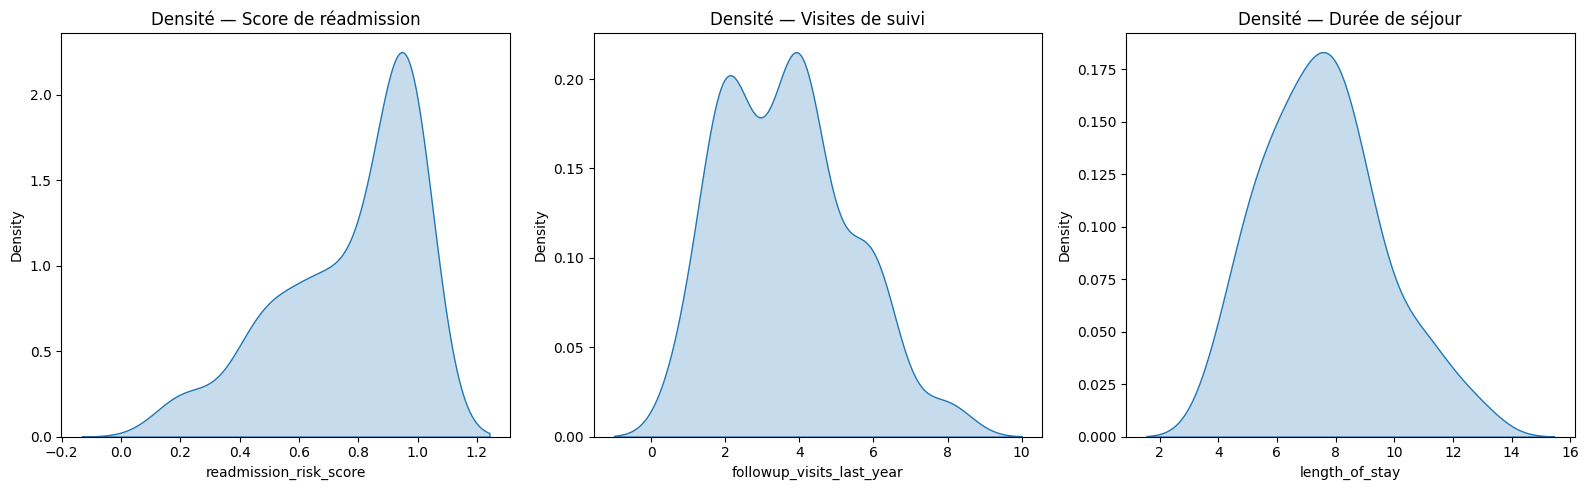

In [34]:
df["readmission_risk_score"] = pd.to_numeric(df["readmission_risk_score"], errors="coerce")
df["followup_visits_last_year"] = pd.to_numeric(df["followup_visits_last_year"], errors="coerce")

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.kdeplot(data=df, x="readmission_risk_score", fill=True, ax=axes[0]).set_title("Densité — Score de réadmission")
sns.kdeplot(data=df, x="followup_visits_last_year", fill=True, ax=axes[1]).set_title("Densité — Visites de suivi")
sns.kdeplot(data=df, x="length_of_stay", fill=True, ax=axes[2]).set_title("Densité — Durée de séjour")

plt.tight_layout()
plt.show()

Score de réadmission
La courbe montre une distribution asymétrique avec un pic très marqué autour de 0,9-1,0. Cela signifie que la majorité des patients ont un score de réadmission élevé, proche de 1. La distribution est concentrée vers les valeurs hautes, ce qui confirme que le risque de réadmission est dominant dans cette population.
Visites de suivi
La courbe présente  deux bosses distinctes, l'une autour de 2 visites et l'autre autour de 4-5 visites. Cela indique qu'il existe deux sous-groupes de patients dans le dataset : ceux qui ont peu de visites de suivi et ceux qui en ont davantage. Cette distribution suggère que les patients ne sont pas homogènes dans leur suivi post-hospitalisation.

Durée de séjour
La courbe est la plus proche d'une distribution normale parmi les trois. Elle est centrée autour de 7-8 jours avec une légère asymétrie vers la droite, indiquant que quelques patients ont des séjours nettement plus longs que la moyenne. La majorité des patients restent donc hospitalisés entre 5 et 10 jours environ.

Boîtes à moustaches

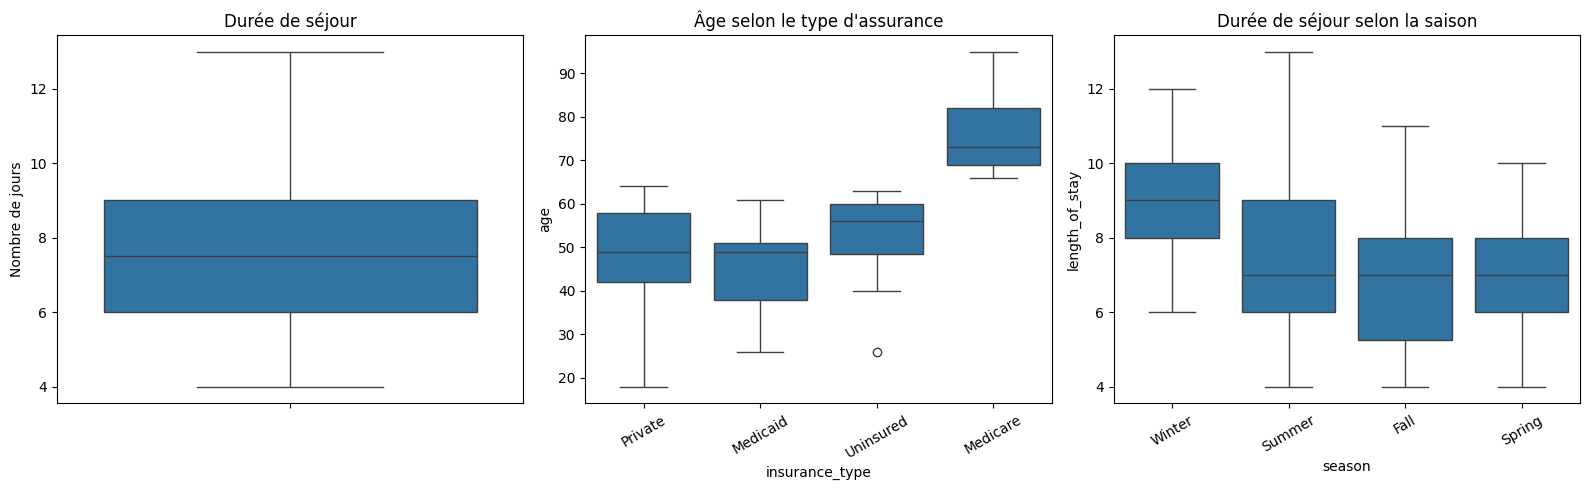

In [35]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.boxplot(y=df["length_of_stay"], ax=axes[0]).set_title("Durée de séjour")
axes[0].set_ylabel("Nombre de jours")

sns.boxplot(x='insurance_type', y='age', data=df, ax=axes[1])
axes[1].set_title("Âge selon le type d'assurance")
axes[1].tick_params(axis='x', rotation=30)

sns.boxplot(x='season', y='length_of_stay', data=df, ax=axes[2])
axes[2].set_title("Durée de séjour selon la saison")
axes[2].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

-Durée de séjour  : La durée de séjour est centrée autour de 7-8 jours avec une dispersion modérée, la majorité des patients restant entre 6 et 9 jours, et quelques cas extrêmes atteignant 4 jours minimum et 13 jours maximum.
-Âge selon le type d'assurance : Les patients Medicare sont nettement plus âgés avec une médiane autour de 75 ans, tandis que les patients Medicaid et à assurance privée sont plus jeunes avec des médianes autour de 45-50 ans. Les patients non assurés présentent une médiane intermédiaire autour de 55 ans avec un outlier notable vers 30 ans, ce qui reflète une logique cohérente où Medicare couvre principalement les personnes âgées de 65 ans et plus.
- Séjour selon saison : Les durées de séjour varient légèrement selon la saison : l'hiver présente les séjours les plus longs avec une médiane autour de 9 jours et une dispersion plus élevée, tandis que l'automne, le printemps et l'été affichent des médianes plus basses autour de 7 jours avec une variabilité similaire entre eux.

Méthode IQR
On applique la règle des **1,5 × IQR** pour filtrer les valeurs aberrantes de `length_of_stay`.

In [36]:
from scipy import stats

iqr = stats.iqr(df['length_of_stay'])
lower = np.quantile(df['length_of_stay'], 0.25) - 1.5 * iqr
upper = np.quantile(df['length_of_stay'], 0.75) + 1.5 * iqr

print(f"Seuil inférieur : {lower:.1f} jours")
print(f"Seuil supérieur : {upper:.1f} jours")

df_clean = df[(df['length_of_stay'] >= lower) & (df['length_of_stay'] <= upper)]
print(f"Taille après filtrage : {df_clean.shape}")

Seuil inférieur : 1.5 jours
Seuil supérieur : 13.5 jours
Taille après filtrage : (106, 16)


**Résultat :** On calcule les bornes inférieure et supérieure au-delà desquelles une valeur
est considérée aberrante. `df_clean` ne contient plus de séjours extrêmement courts ou longs,
rendant les données plus **homogènes et fiables** pour la modélisation.

Graphiques relationnels et bivariés

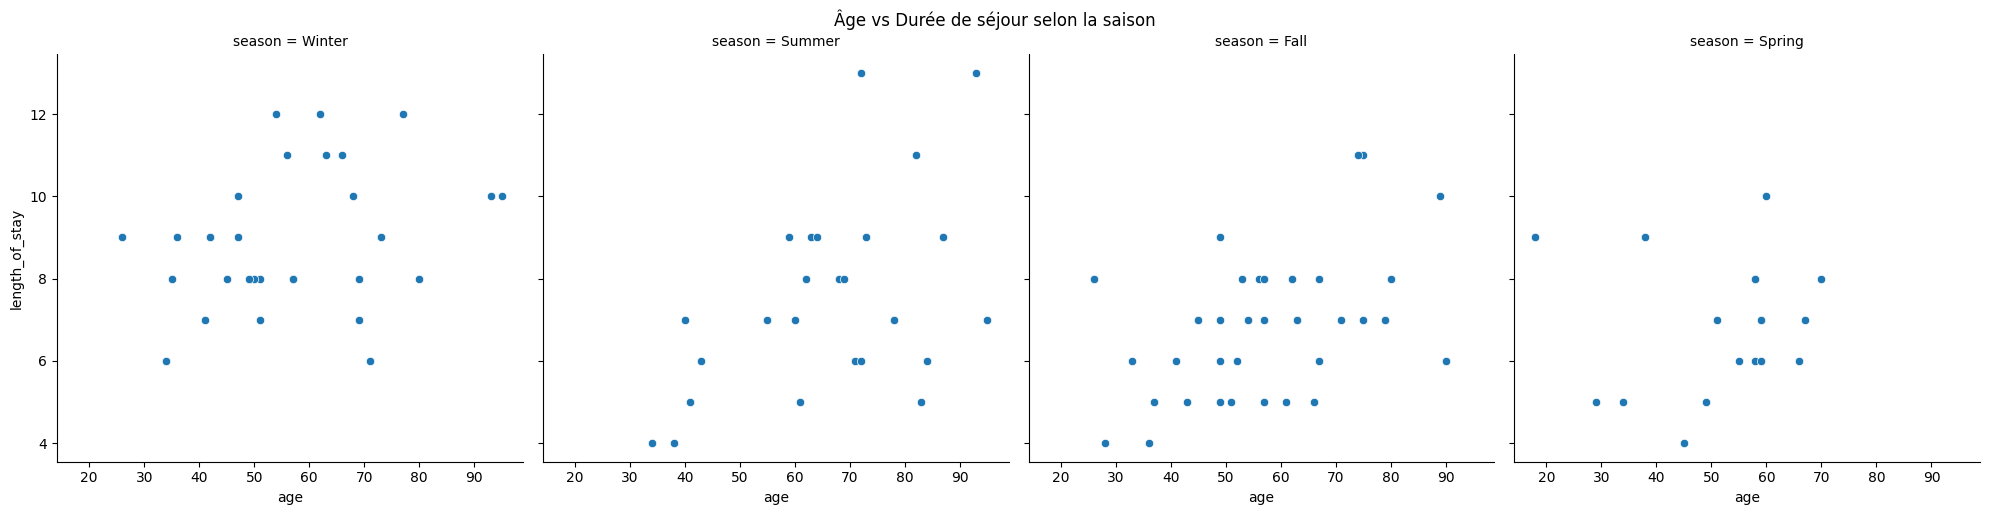

In [37]:
sns.relplot(x='age', y='length_of_stay', col='season', kind='scatter', data=df)
plt.suptitle("Âge vs Durée de séjour selon la saison", y=1.02)
plt.show()

Âge vs Durée de séjour selon la saison : Les nuages de points ne montrent pas de tendance claire entre l'âge et la durée de séjour, quelle que soit la saison. Les points sont dispersés de manière aléatoire sur toutes les tranches d'âge (20 à 90 ans), ce qui suggère que l'âge seul n'explique pas la durée d'hospitalisation. Ce constat est similaire pour les quatre saisons,

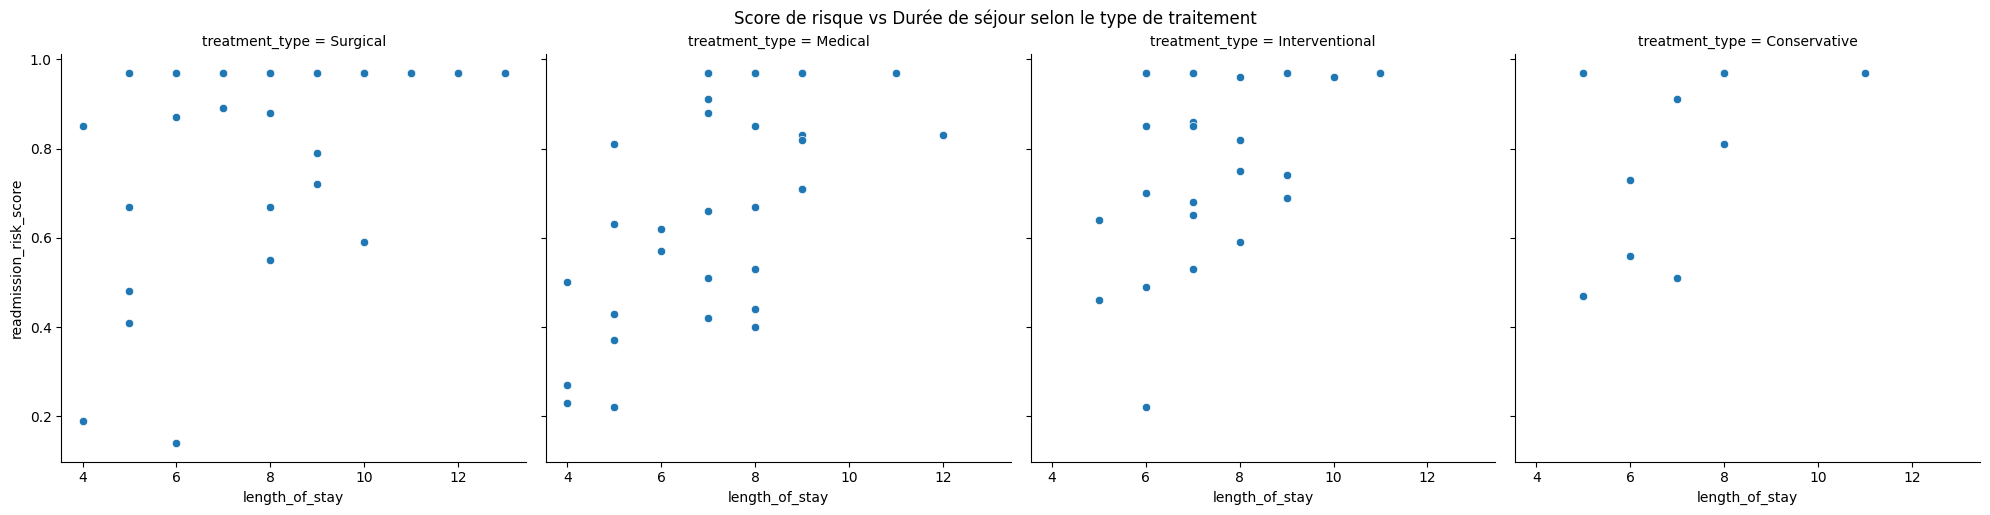

In [38]:
sns.relplot(x='length_of_stay', y='readmission_risk_score', col='treatment_type', kind='scatter', data=df)
plt.suptitle("Score de risque vs Durée de séjour selon le type de traitement", y=1.02)
plt.show()

Score de risque vs Durée de séjour selon le type de traitement : Les patients chirurgicaux et interventionnels ont des scores de risque majoritairement élevés, proches de 1,0, quelle que soit leur durée de séjour. Le traitement médical montre des scores plus variés, allant de 0,2 à 1,0. Le traitement conservateur, peu représenté, affiche également des scores plutôt élevés. Aucun type de traitement ne montre de lien clair entre la durée de séjour et le score de réadmission.

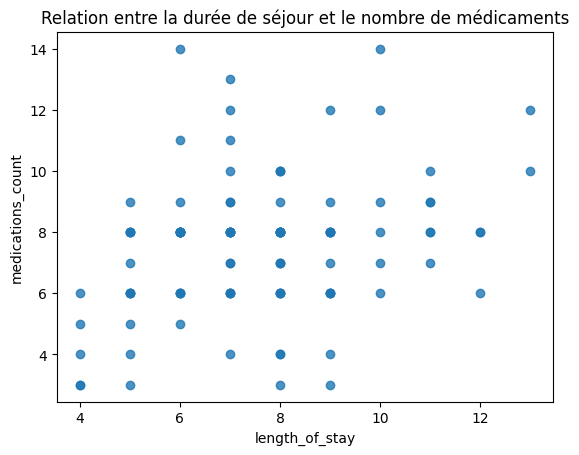

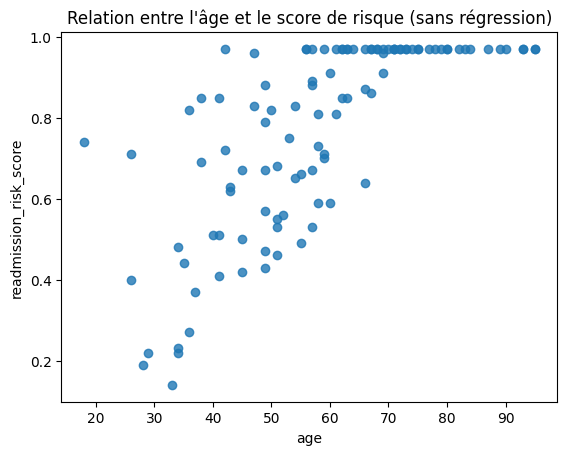

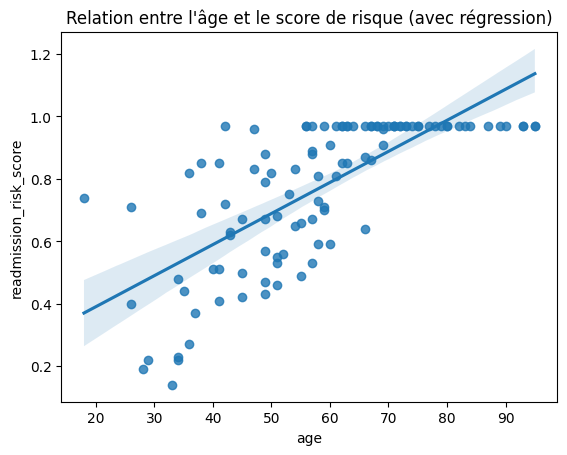

In [39]:

sns.regplot(x='length_of_stay', y='medications_count', fit_reg=False, data=df)
plt.title("Relation entre la durée de séjour et le nombre de médicaments")
plt.show()

sns.regplot(x='age', y='readmission_risk_score', fit_reg=False, data=df)
plt.title("Relation entre l'âge et le score de risque (sans régression)")
plt.show()

sns.regplot(x='age', y='readmission_risk_score', fit_reg=True, data=df)
plt.title("Relation entre l'âge et le score de risque (avec régression)")
plt.show()

Graphique 1 : Relation durée de séjour vs médicaments
Ce graphique montre la relation entre le nombre de jours à l'hôpital et le nombre de médicaments reçus. On observe que plus le séjour est long, plus le patient reçoit de médicaments.
Graphique 2 : Relation âge vs score de risque 
Ce graphique montre comment l'âge influence le risque de réadmission. On voit clairement une tendance : plus les patients sont âgés, plus leur score de risque est élevé. Un patient de 30 ans a un score autour de 0.2 tandis qu'un patient de 80 ans a un score autour de 0.9. 
Graphique 3 : Relation âge vs score de risque 
C'est le même graphique que le précédent, mais avec une ligne bleue qui montre la tendance générale. Cette ligne de régression confirme la relation positive entre l'âge et le risque de réadmission. Plus on avance en âge, plus le risque augmente de manière prévisible. Cette ligne permet de prédire le score de risque en fonction de l'âge."

Countplots et Pie charts

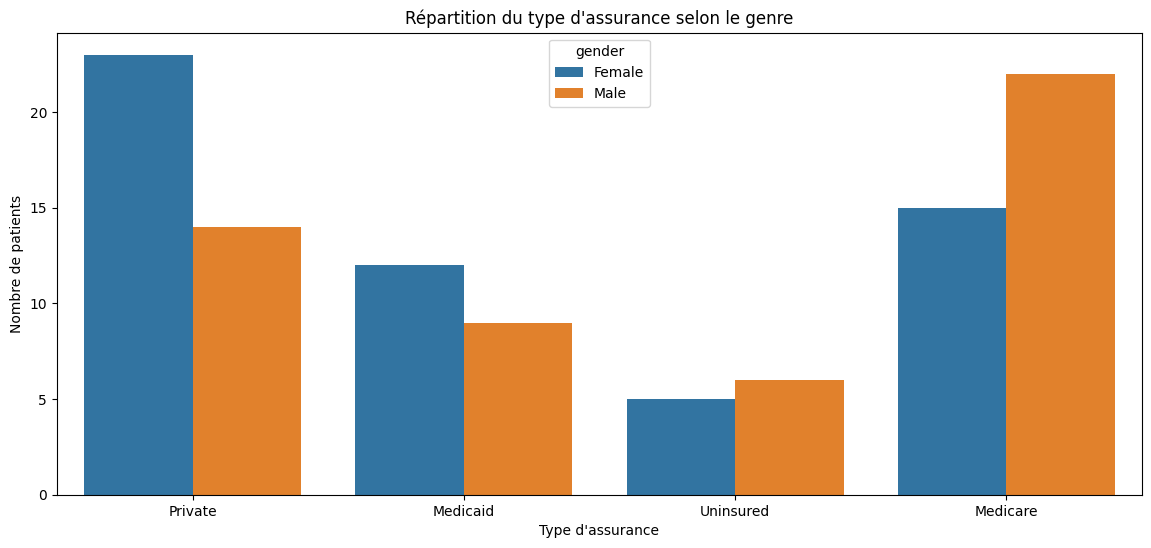

In [40]:
plt.figure(figsize=(14, 6))
sns.countplot(x='insurance_type', hue='gender', data=df)
plt.title("Répartition du type d'assurance selon le genre")
plt.xlabel("Type d'assurance")
plt.ylabel("Nombre de patients")
plt.show()

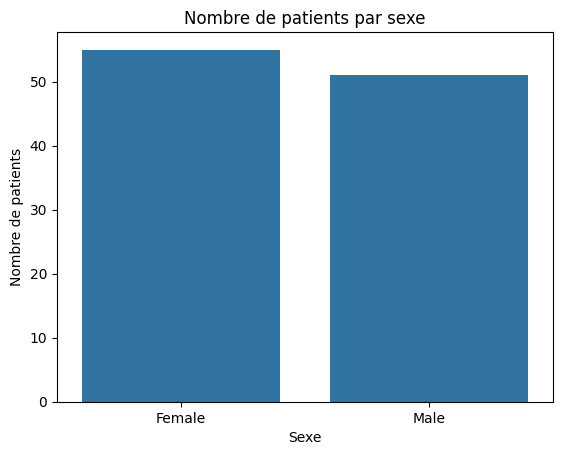

In [41]:
# Countplot genre
sns.countplot(data=df, x='gender')
plt.title('Nombre de patients par sexe')
plt.xlabel('Sexe')
plt.ylabel('Nombre de patients')
plt.show()

**Interprétation :** Ce graphique croise le type d'assurance avec la réadmission.
On peut observer si certains types d'assurance sont associés à des taux de réadmission plus élevés,
ce qui pourrait indiquer des différences d'accès aux soins.

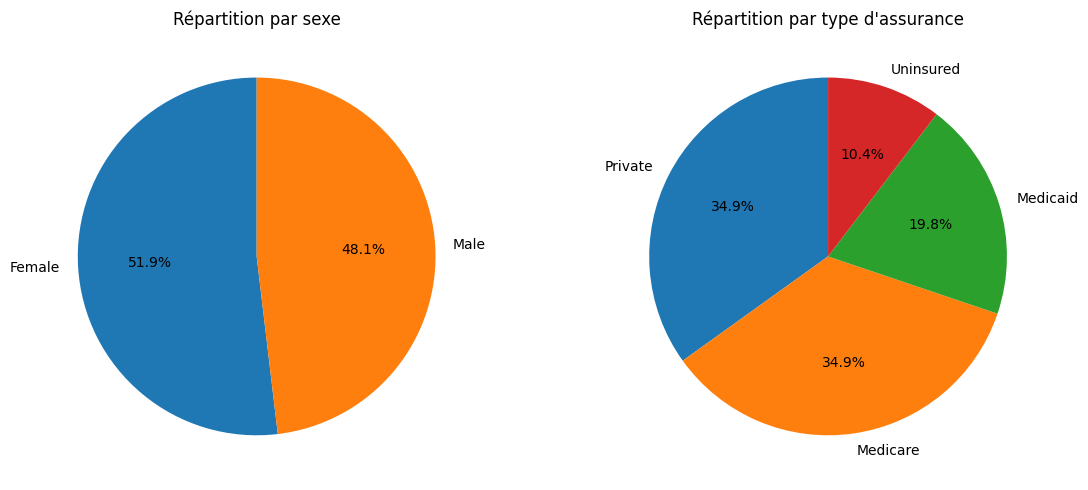

In [42]:
# Camembert genre
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

df['gender'].value_counts().plot(
    kind='pie', autopct='%1.1f%%', startangle=90,
    title='Répartition par sexe', ax=axes[0])
axes[0].set_ylabel('')

df['insurance_type'].value_counts().plot(
    kind='pie', autopct='%1.1f%%', startangle=90,
    title="Répartition par type d'assurance", ax=axes[1])
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

Genre: 52,3% de femmes et 47,7% d'hommes — répartition parfaite.
Assurance : Privée et Medicare dominent avec 35% chacune.19.8 sont medicaid et 10.4 n'ont pas d'assurance 

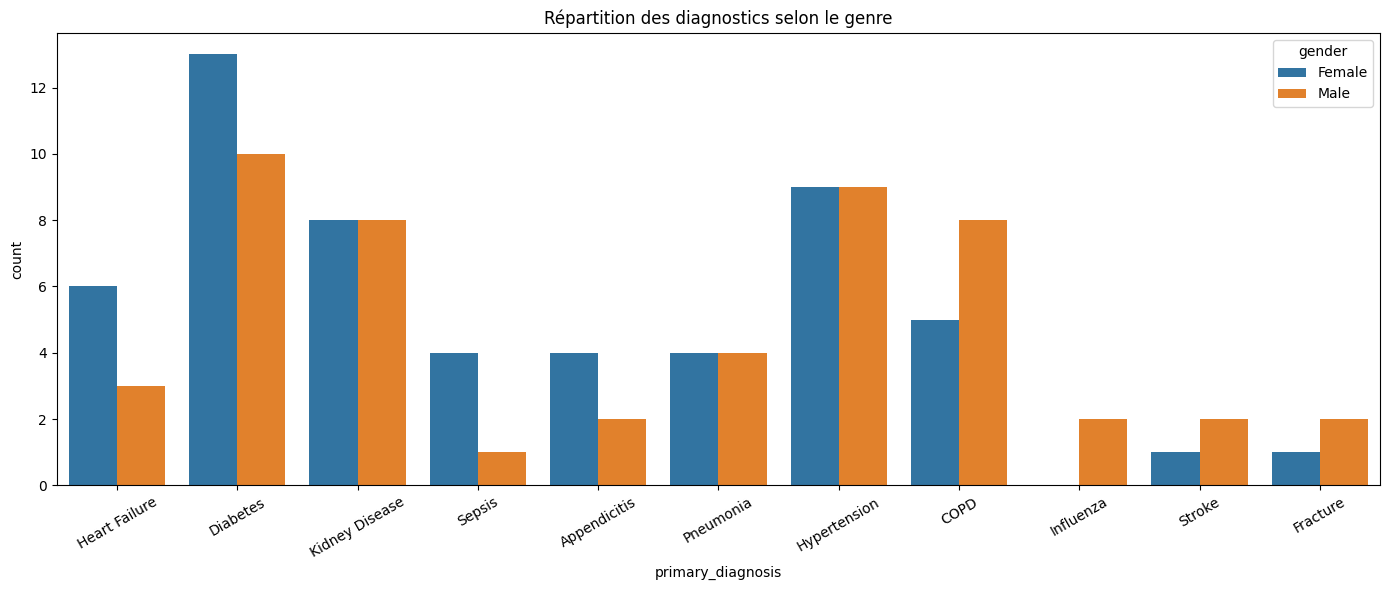

In [43]:
plt.figure(figsize=(14, 6))
sns.countplot(x='primary_diagnosis', hue='gender', data=df)
plt.title("Répartition des diagnostics selon le genre")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

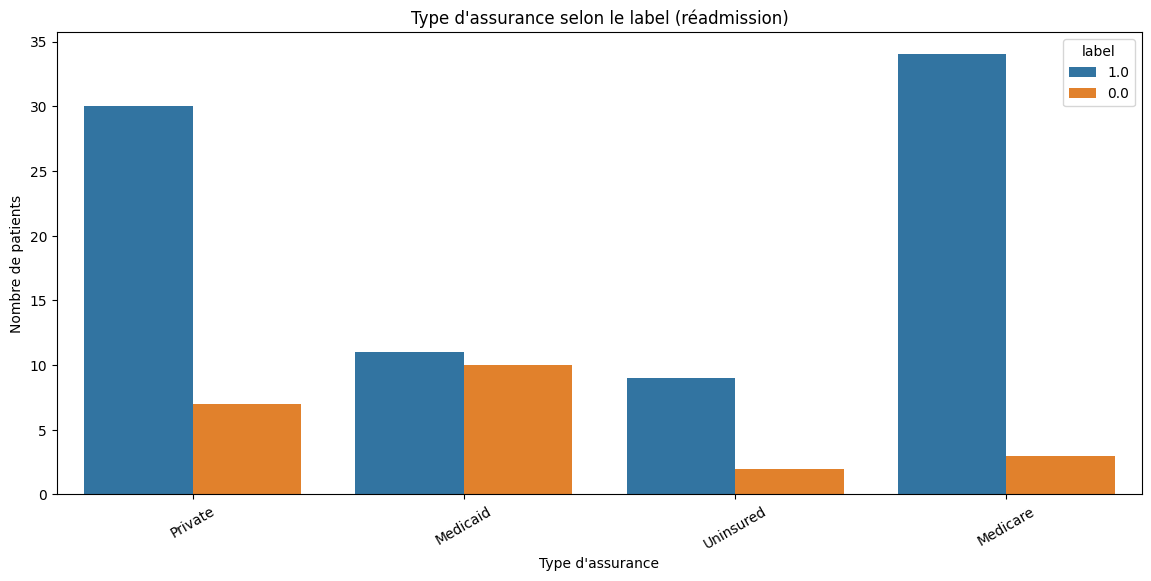

In [44]:

plt.figure(figsize=(14, 6))
sns.countplot(x='insurance_type', hue='label', data=df)
plt.title("Type d'assurance selon le label (réadmission)")
plt.xlabel("Type d'assurance")
plt.ylabel("Nombre de patients")
plt.xticks(rotation=30)
plt.show()

Analyse:Ce graphique montre les différents diagnostics des patients, séparés par genre. On remarque que le diabète est la maladie la plus courante, affectant 13 femmes et 10 hommes. L'hypertension et la maladie rénale sont aussi très fréquentes chez les deux sexes. Certains diagnostics affectent plus les femmes : l'insuffisance cardiaque touche 6 femmes pour 3 hommes. D'autres affectent plus les hommes : la COPD touche 8 hommes pour 5 femmes. Les maladies infectieuses comme la pneumonie et la grippe sont rares. Globalement, les maladies chroniques (diabète, hypertension, maladie rénale) dominent dans notre dataset, ce qui reflète les patients hospitalisés.

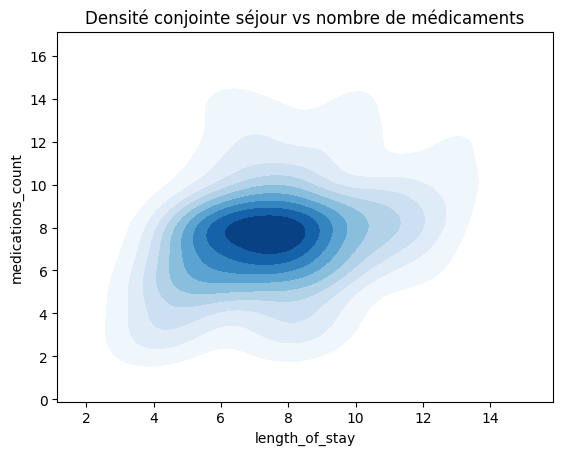

In [45]:
# Densité conjointe séjour vs médicaments
sns.kdeplot(
    x="length_of_stay", y="medications_count",
    cmap="Blues", fill=True, data=df
).set_title("Densité conjointe séjour vs nombre de médicaments")
plt.show()

Ce graphique montre la concentration des patients selon la durée de leur séjour et le nombre de médicaments reçus. On voit une tache bleu foncé très concentrée autour de 6-8 jours de séjour et 6-8 médicaments. Cela signifie que la majorité des patients reste 6-8 jours et reçoit 6-8 médicaments. La forme allongée du graphique montre une relation positive claire : plus les patients restent longtemps à l'hôpital, plus ils reçoivent de médicaments. Les patients qui restent 12-14 jours reçoivent aussi plus de médicaments (10-14). Cette relation confirme que les cas plus graves (plus long séjour) nécessitent plus de traitement (plus de médicaments)

Corrélations et Relations entre Variables

On sauvegarde puis recharge le dataset nettoyé pour repartir d'une base propre.

In [46]:
df.to_csv('ma_base_modifiee.csv', index=False)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from warnings import filterwarnings
filterwarnings('ignore')

df = pd.read_csv('ma_base_modifiee.csv')
print("Dataset rechargé :", df.shape)

Dataset rechargé : (106, 16)


### 5.2 Imputation des valeurs manquantes restantes
On remplace les NaN éventuels des colonnes numériques par leur **moyenne**.
Cette imputation simple permet de conserver toutes les lignes pour les analyses suivantes.

In [47]:
num_cols = ['age', 'comorbidities_count', 'length_of_stay',
            'medications_count', 'followup_visits_last_year',
            'prev_readmissions', 'readmission_risk_score', 'label']

df.fillna(df[num_cols].mean(), inplace=True)
df.isna().sum()

admission_date               0
season                       0
age                          0
gender                       0
region                       0
primary_diagnosis            0
comorbidities_count          0
length_of_stay               0
treatment_type               0
medications_count            0
followup_visits_last_year    0
prev_readmissions            0
insurance_type               0
discharge_disposition        0
readmission_risk_score       0
label                        0
dtype: int64

Test de corrélation de Pearson — Séjour vs Médicaments

In [48]:
from scipy import stats

corr, pval = stats.pearsonr(df['length_of_stay'], df['medications_count'])

print(f"Coefficient de Pearson : {corr:.4f}")
print(f"P-valeur               : {pval:.4e}")

if pval < 0.05:
    print("→ Corrélation statistiquement significative (p < 0.05)")
else:
    print("→ Pas de corrélation significative")

Coefficient de Pearson : 0.3012
P-valeur               : 1.7045e-03
→ Corrélation statistiquement significative (p < 0.05)


Résultat : r = 0,367, p = 0,0081
Il existe une corrélation positive modérée entre la durée de séjour et le nombre de médicaments,
statistiquement significative. Plus un patient reste longtemps à l'hôpital, plus il tend à recevoir
de médicaments — ce qui est  cohérent.

Heatmap de corrélations
La heatmap permet de visualiser simultanément toutes les corrélations entre variables numériques.
Le masque triangulaire évite la redondance (la matrice est symétrique).

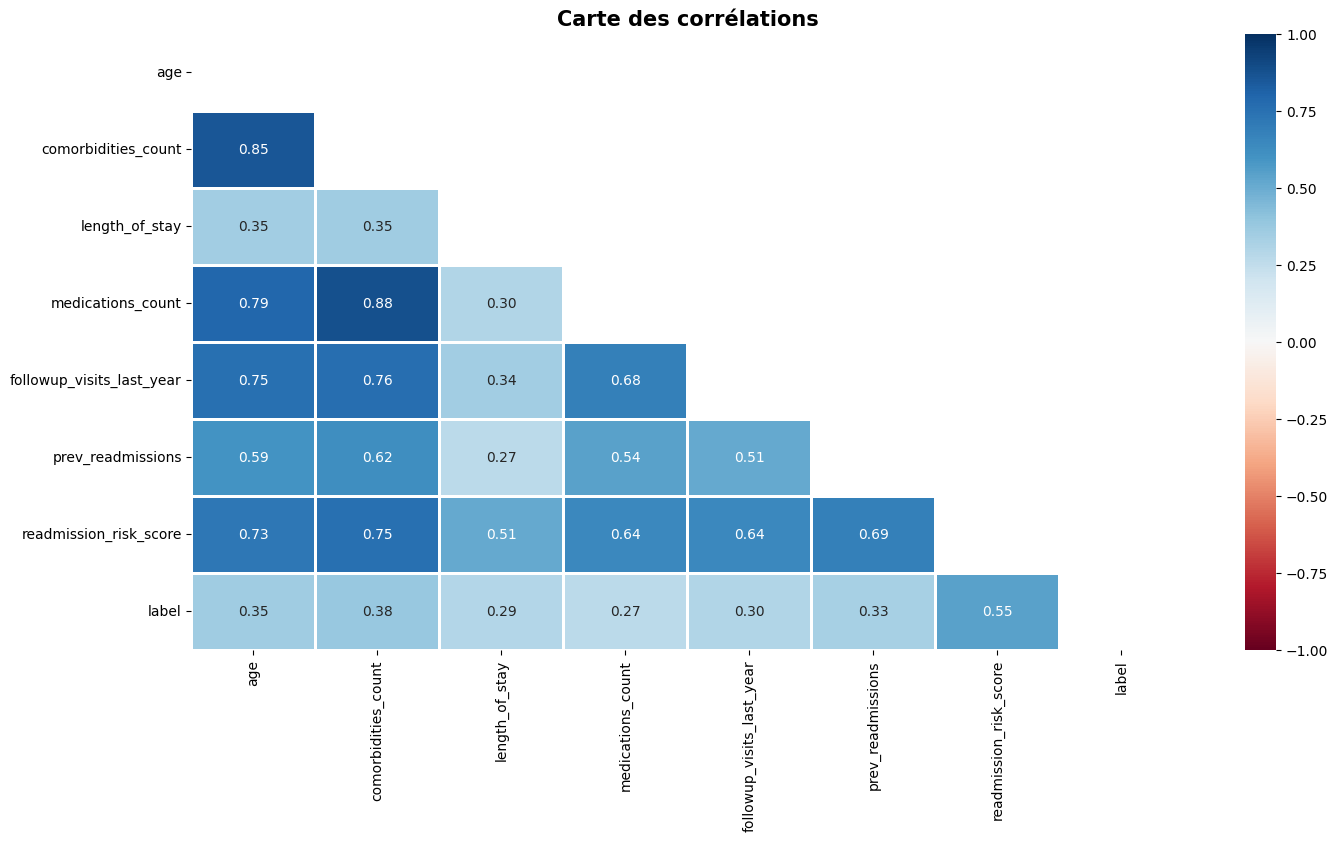

In [49]:
import numpy as np

num_cols = ['age', 'comorbidities_count', 'length_of_stay',
            'medications_count', 'followup_visits_last_year',
            'prev_readmissions', 'readmission_risk_score', 'label']

plt.figure(figsize=(16, 8))
mask = np.triu(np.ones_like(df[num_cols].corr(), dtype=bool))

sns.heatmap(
    df[num_cols].corr(),
    mask=mask, center=0, cmap='RdBu',
    linewidths=1, annot=True, fmt=".2f",
    vmin=-1, vmax=1
)

plt.title('Carte des corrélations', fontsize=15, fontweight="bold")
plt.show()

**Interprétation :** Les valeurs proches de **+1** indiquent une corrélation positive forte,
celles proches de **-1** une corrélation négative forte, et celles proches de **0** l'absence de relation.
On observe notamment que `readmission_risk_score` et `label` sont positivement corrélés,
validant la pertinence du score comme indicateur de réadmission.

### 5.5 Corrélation par genre
On calcule séparément la corrélation séjour/médicaments pour les femmes et les hommes,
afin de voir si la relation diffère selon le genre.

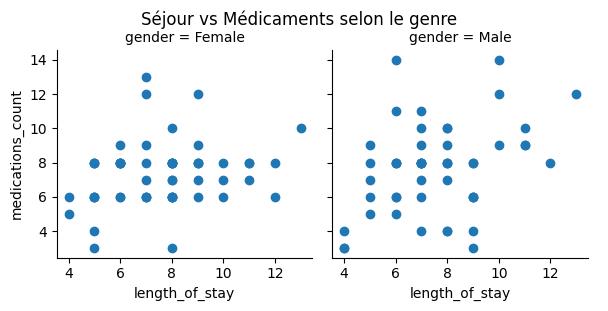

In [50]:
sns.FacetGrid(df, col="gender").map(
    plt.scatter, "length_of_stay", "medications_count"
).add_legend()
plt.suptitle("Séjour vs Médicaments selon le genre", y=1.02)
plt.show()

In [51]:
for genre in df['gender'].unique():
    subset = df[df['gender'] == genre]
    corr, pval = stats.pearsonr(subset['length_of_stay'], subset['medications_count'])
    print(f"{genre} : r = {corr:.3f}, p = {pval:.4e}")

Female : r = 0.232, p = 8.7616e-02
Male : r = 0.367, p = 8.0943e-03


La corrélation entre durée du séjour et médicaments est très faible (0.232). Cela n'est pas statistiquement significatif (p = 0.087 > 0.05). Donc chez les femmes, il n'y a pas de relation claire entre les jours passés à l'hôpital et le nombre de médicaments.

 Diagnostic et assurance

In [52]:
pd.crosstab(df['primary_diagnosis'], df['insurance_type'])

insurance_type,Medicaid,Medicare,Private,Uninsured
primary_diagnosis,,,,
Appendicitis,2,3,0,1
COPD,4,4,5,0
Diabetes,5,9,8,1
Fracture,0,0,1,2
Heart Failure,1,3,5,0
Hypertension,5,4,7,2
Influenza,1,1,0,0
Kidney Disease,0,7,6,3
Pneumonia,2,2,3,1


Ce tableau montre combien de patients ont chaque diagnostic selon leur type d'assurance.
Le diabète est le diagnostic le plus courant (23 patients au total). Medicare couvre le plus de patients diabétiques (9). Les fractures sont rares (3 patients). La plupart des diagnostics ont au moins quelques patients dans chaque catégorie d'assurance.


In [53]:

pd.crosstab(df['primary_diagnosis'], df['insurance_type']).apply(
    lambda z: z / z.sum() * 100, axis=1
).round(1)

insurance_type,Medicaid,Medicare,Private,Uninsured
primary_diagnosis,,,,
Appendicitis,33.3,50.0,0.0,16.7
COPD,30.8,30.8,38.5,0.0
Diabetes,21.7,39.1,34.8,4.3
Fracture,0.0,0.0,33.3,66.7
Heart Failure,11.1,33.3,55.6,0.0
Hypertension,27.8,22.2,38.9,11.1
Influenza,50.0,50.0,0.0,0.0
Kidney Disease,0.0,43.8,37.5,18.8
Pneumonia,25.0,25.0,37.5,12.5


Ce tableau montre comment l'assurance se répartit (en pourcentages) pour chaque diagnostic.
Pour le diabète, l'assurance se répartit bien : 39,1% Medicare, 34,8% Private, 21,7% Medicaid. Pour les fractures, 66,7% sont sans assurance (Uninsured), ce qui est anormal. Medicare domine les maladies rénales (41,8%). Globalement, il n'y a pas de lien fort entre le diagnostic et l'assurance.

In [54]:
# Tableau croisé genre × diagnostic × assurance
pd.crosstab(
    [df['gender'], df['primary_diagnosis']],
    df['insurance_type']
).apply(lambda x: x / x.sum(), axis=1).round(3)

insurance_type            Medicaid  Medicare  Private  Uninsured
gender primary_diagnosis                                        
Female Appendicitis          0.500     0.250    0.000      0.250
       COPD                  0.400     0.400    0.200      0.000
       Diabetes              0.231     0.231    0.462      0.077
       Fracture              0.000     0.000    1.000      0.000
       Heart Failure         0.167     0.333    0.500      0.000
       Hypertension          0.333     0.111    0.444      0.111
       Kidney Disease        0.000     0.375    0.500      0.125
       Pneumonia             0.000     0.000    0.750      0.250
       Sepsis                0.250     0.500    0.250      0.000
       Stroke                0.000     1.000    0.000      0.000
Male   Appendicitis          0.000     1.000    0.000      0.000
       COPD                  0.250     0.250    0.500      0.000
       Diabetes              0.200     0.600    0.200      0.000
       Fracture              0.000     0.000    0.000      1.000
       Heart Failure         0.000     0.333    0.667      0.000
       Hypertension          0.222     0.333    0.333      0.111
       Influenza             0.500     0.500    0.000      0.000
       Kidney Disease        0.000     0.500    0.250      0.250
       Pneumonia             0.500     0.500    0.000      0.000
       Sepsis                0.000     0.000    0.000      1.000
       Stroke                0.000     0.500    0.500      0.000

Chez les femmes, le diabète se répartit entre Private (46,2%) et Medicare (23,1%). Les fractures affectent surtout les femmes assurées privément (100%). Heart Failure touche plus les femmes Private (50%). Les patterns sont similaires au tableau précédent mais avec des variations selon le genre.

**Interprétation :** Ces tableaux croisés permettent d'analyser les relations entre
le diagnostic principal, le type d'assurance et le genre. Par exemple, on peut identifier
si certains diagnostics sont plus fréquents chez les patients non assurés.

Règles d'Association

Installation et import de mlxtend

In [55]:
import sys
!{sys.executable} -m pip install mlxtend --quiet

from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules
print("mlxtend importé avec succès")

mlxtend importé avec succès


In [56]:
def build_transaction(row):
    items = []
    if pd.notna(row['primary_diagnosis']):
        items.append('Diag_' + str(row['primary_diagnosis']))
    if pd.notna(row['treatment_type']):
        items.append('Trait_' + str(row['treatment_type']))
    if pd.notna(row['insurance_type']):
        items.append('Assur_' + str(row['insurance_type']))
    if pd.notna(row['discharge_disposition']):
        items.append('Sortie_' + str(row['discharge_disposition']))
    if pd.notna(row['season']):
        items.append('Saison_' + str(row['season']))
    if pd.notna(row['gender']):
        items.append('Genre_' + str(row['gender']))
    if pd.notna(row['region']):
        items.append('Region_' + str(row['region']))
    if row['readmission_risk_score'] >= 0.7:
        items.append('RisqueEleve')
    else:
        items.append('RisqueFaible')
    return items

transactions = df.apply(build_transaction, axis=1).tolist()
print(f"Nombre de transactions : {len(transactions)}")
print("Exemple :", transactions[0])

Nombre de transactions : 106
Exemple : ['Diag_Heart Failure', 'Trait_Surgical', 'Assur_Private', 'Sortie_Home Health', 'Saison_Winter', 'Genre_Female', 'Region_Central', 'RisqueEleve']


Nous avons créé une matrice de transactions en encodant chaque patient sous forme d'items binaires (0 ou 1). Chaque item représente une caractéristique du patient : son diagnostic, son type de traitement, son assurance, etc. Cette matrice permet d'identifier les associations entre différentes caractéristiques des patients et leur risque de réadmission.

Avec `TransactionEncoder` on a Chaque ligne correspond à un patient, chaque colonne à un item possible.

In [57]:
encoder = TransactionEncoder()
encoded_array = encoder.fit(transactions).transform(transactions)
df_encoded = pd.DataFrame(encoded_array, columns=encoder.columns_)

print(df_encoded.shape)
df_encoded.head()

(106, 36)


,Assur_Medicaid,Assur_Medicare,Assur_Private,Assur_Uninsured,Diag_Appendicitis,Diag_COPD,Diag_Diabetes,Diag_Fracture,Diag_Heart Failure,Diag_Hypertension,...,Saison_Summer,Saison_Winter,Sortie_Home,Sortie_Home Health,Sortie_Rehab,Sortie_Skilled Nursing,Trait_Conservative,Trait_Interventional,Trait_Medical,Trait_Surgical
0,False,False,True,False,False,False,False,False,True,False,...,False,True,False,True,False,False,False,False,False,True
1,True,False,False,False,False,False,True,False,False,False,...,True,False,False,True,False,False,False,False,True,False
2,True,False,False,False,False,False,True,False,False,False,...,True,False,False,True,False,False,False,False,True,False
3,False,False,True,False,False,False,False,False,False,False,...,False,False,False,True,False,False,False,False,True,False
4,False,False,False,True,False,False,False,False,False,False,...,False,True,False,True,False,False,False,False,False,True


L'algorithme Apriori extrait les ensembles d'items qui apparaissent ensemble dans au moins
`min_support = 10%` des transactions. 

In [58]:
frequent_itemsets = apriori(df_encoded, min_support=0.1, use_colnames=True)
frequent_itemsets = frequent_itemsets.sort_values('support', ascending=False)

print(f"Nombre d'itemsets fréquents : {len(frequent_itemsets)}")
frequent_itemsets.head(20)

Nombre d'itemsets fréquents : 165


,support,itemsets
21,0.745283,(Sortie_Home Health)
15,0.660377,(RisqueEleve)
8,0.518868,(Genre_Female)
9,0.481132,(Genre_Male)
94,0.471698,"(RisqueEleve, Sortie_Home Health)"
63,0.433962,"(Genre_Female, Sortie_Home Health)"
1,0.349057,(Assur_Medicare)
2,0.349057,(Assur_Private)
70,0.339623,"(RisqueEleve, Genre_Male)"
31,0.339623,"(RisqueEleve, Assur_Medicare)"


--165 itemsets fréquents extraits. Les items les plus fréquents sont
ceux présents dans au moins 10% des patients (≥ 11 patients sur 106).
Les résultats les plus importants :
*Sortie_Home Health est l'item le plus fréquent avec un support de 74,5%.(presque 3 patients sur 4 ont ce type de sortie, ce qui montre que la majorité des patients rentrent chez eux après leur prise en charge.)
*RisqueEleve apparaît seul avec 66% de support.
*La combinaison Sortie_Home Health + RisqueEleve a un support de 47% .
*Genre_Female (51,8%) et Genre_Male (48,1%) sont bien équilibrés

Génération des règles d'association
On génère les règles de la forme **SI {antécédents} → ALORS {conséquents}**.
Les trois métriques clés :
- **Support** 
- **Confiance** 
- **Lift**

In [59]:
rules = association_rules(frequent_itemsets, metric='lift', min_threshold=1.2)
rules = rules.sort_values('lift', ascending=False)

print(f"Nombre total de règles : {len(rules)}")
rules[['antecedents', 'consequents', 'support', 'confidence', 'lift']].head(20)

Nombre total de règles : 234


,antecedents,consequents,support,confidence,lift
50,"(RisqueEleve, Sortie_Skilled Nursing)",(Assur_Medicare),0.150943,0.842105,2.412518
55,(Assur_Medicare),"(RisqueEleve, Sortie_Skilled Nursing)",0.150943,0.432432,2.412518
51,"(RisqueEleve, Assur_Medicare)",(Sortie_Skilled Nursing),0.150943,0.444444,2.355556
54,(Sortie_Skilled Nursing),"(RisqueEleve, Assur_Medicare)",0.150943,0.800000,2.355556
58,(Sortie_Skilled Nursing),(Assur_Medicare),0.150943,0.800000,2.291892
59,(Assur_Medicare),(Sortie_Skilled Nursing),0.150943,0.432432,2.291892
146,(Sortie_Skilled Nursing),"(RisqueEleve, Trait_Surgical)",0.113208,0.600000,2.271429
143,"(RisqueEleve, Trait_Surgical)",(Sortie_Skilled Nursing),0.113208,0.428571,2.271429
156,"(RisqueEleve, Genre_Male, Trait_Surgical)",(Assur_Medicare),0.113208,0.750000,2.148649
165,(Assur_Medicare),"(RisqueEleve, Genre_Male, Trait_Surgical)",0.113208,0.324324,2.148649


L'algorithme Apriori a généré 234 règles d'association avec un lift ≥ 1,2. Les règles avec le lift le plus élevé représentent les associations les plus fortes et les plus intéressantes entre les caractéristiques des patients. Par exemple, la règle la plus significative (lift = 2,41) indique que les patients en soins infirmiers spécialisés et à risque élevé sont très fortement associés à une assurance Medicare.

 Visualisation — Support vs Confiance
Ce nuage de points permet de visualiser l'ensemble des règles selon leurs trois métriques simultanément :
Support (axe x), Confiance (axe y), et Lift (couleur).

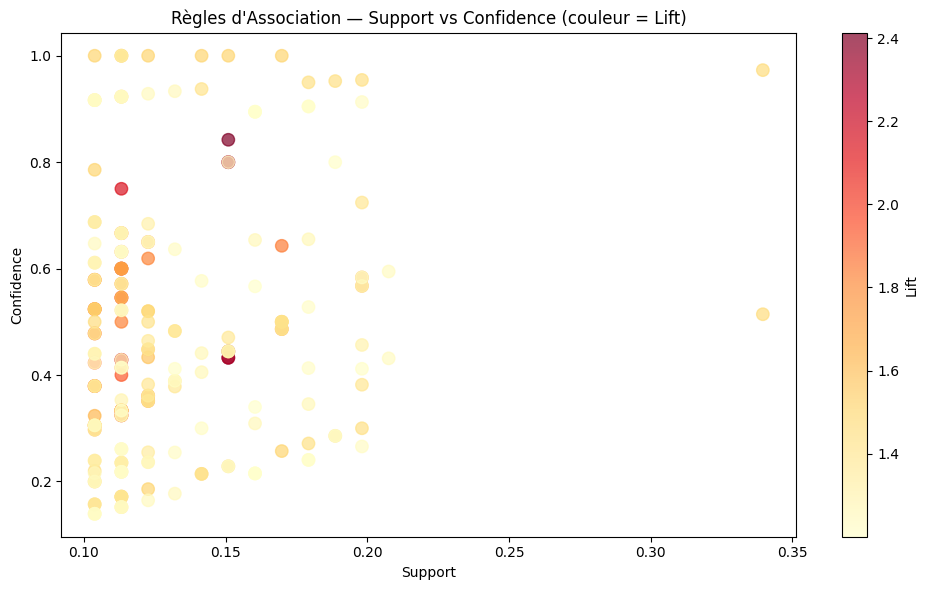

In [60]:
plt.figure(figsize=(10, 6))
plt.scatter(rules['support'], rules['confidence'],
            c=rules['lift'], cmap='YlOrRd', alpha=0.7, s=80)
plt.colorbar(label='Lift')
plt.xlabel('Support')
plt.ylabel('Confidence')
plt.title("Règles d'Association — Support vs Confidence (couleur = Lift)")
plt.tight_layout()
plt.show()

Ce graphique visualise les 234 règles d'association selon leurs trois métriques simultanément. On remarque que la majorité des règles se concentrent entre un support de 0,10 et 0,20.Les points en haut à droite représentent les meilleures règles
(support et confiance élevés). Les couleurs chaudes (rouge/orange) indiquent un lift élevé,
signifiant une association particulièrement forte entre les items.

Règles pointant vers un risque élevé de réadmission
Ces règles identifient les profils de patients à fort risque de réadmission.

In [61]:
risque_rules = rules[rules['consequents'].apply(lambda x: 'RisqueEleve' in x)]
risque_rules = risque_rules.sort_values('confidence', ascending=False)

print(f"Règles pointant vers un risque élevé : {len(risque_rules)}")
risque_rules[['antecedents', 'consequents', 'support', 'confidence', 'lift']].head(10)

Règles pointant vers un risque élevé : 43


,antecedents,consequents,support,confidence,lift
157,"(Genre_Male, Trait_Surgical, Assur_Medicare)",(RisqueEleve),0.113208,1.000000,1.514286
65,"(Genre_Female, Assur_Medicare)",(RisqueEleve),0.141509,1.000000,1.514286
203,"(Diag_Kidney Disease, Sortie_Home Health)",(RisqueEleve),0.103774,1.000000,1.514286
83,"(Saison_Summer, Assur_Medicare)",(RisqueEleve),0.122642,1.000000,1.514286
144,"(Sortie_Skilled Nursing, Trait_Surgical)",(RisqueEleve),0.113208,1.000000,1.514286
32,"(Trait_Surgical, Assur_Medicare)",(RisqueEleve),0.169811,1.000000,1.514286
52,"(Sortie_Skilled Nursing, Assur_Medicare)",(RisqueEleve),0.150943,1.000000,1.514286
1,(Assur_Medicare),(RisqueEleve),0.339623,0.972973,1.473359
6,"(Genre_Male, Assur_Medicare)",(RisqueEleve),0.198113,0.954545,1.445455
18,"(Sortie_Home Health, Assur_Medicare)",(RisqueEleve),0.188679,0.952381,1.442177


On a trouvé 43 règles qui mènent vers un risque élevé.
Les 6 premières règles ont toutes une confiance de 100%, ça veut dire :
Si un patient est Homme + Medicare + Chirurgie → il est forcément à risque élevé
Si un patient est en Soins Spécialisés + Chirurgie → il est forcément à risque élevé
Si un patient a une Maladie Rénale → il est forcément à risque élevé
Si un patient a Medicare + Été → il est forcément à risque élevé
La règle la plus fréquente est Medicare seul (support = 0,34) avec une confiance de 97%, ce qui veut dire que presque tous les patients Medicare sont à risque élevé.



---
## PARTIE 7 — Clustering K-Means

### 7.1 Préparation des données et normalisation
On sélectionne les 7 variables numériques et on les normalise avec `StandardScaler`.
La normalisation est indispensable pour le K-Means, car l'algorithme est sensible aux échelles
différentes des variables (ex: age en dizaines vs score en décimales).

In [62]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

features = ['age', 'comorbidities_count', 'length_of_stay',
            'medications_count', 'followup_visits_last_year',
            'prev_readmissions', 'readmission_risk_score']

X = df[features].copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Dimensions :", X_scaled.shape)

Dimensions : (106, 7)


Méthode du coude — Choix du nombre optimal de clusters


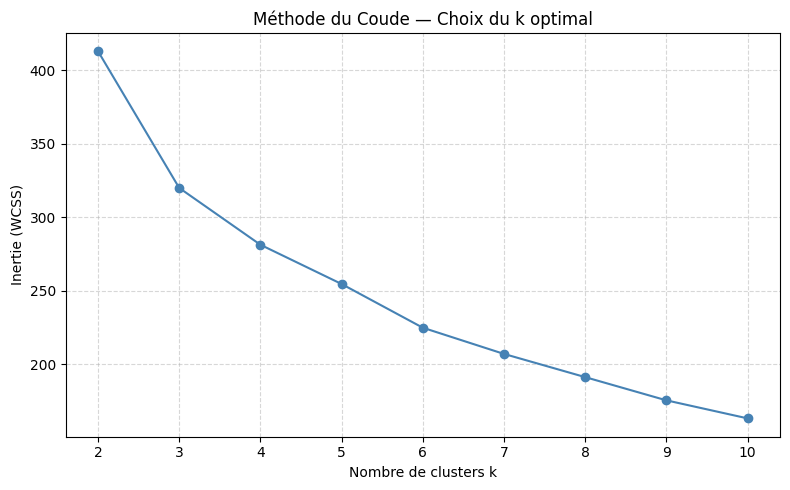

In [63]:
inertia = []
K_range = range(2, 11)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertia.append(km.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(K_range, inertia, marker='o', color='steelblue')
plt.xlabel('Nombre de clusters k')
plt.ylabel('Inertie (WCSS)')
plt.title('Méthode du Coude — Choix du k optimal')
plt.xticks(K_range)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Sur le graphique, on voit que la courbe descend rapidement jusqu'à k = 4, puis après elle continue à baisser mais de façon beaucoup plus lente. Ce point de rupture à k = 4 représente le "coude".
On choisit donc k = 4 comme nombre optimal de clusters .

Application du K-Means avec k = 4

In [64]:
k_optimal = 4

kmeans = KMeans(n_clusters=k_optimal, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X_scaled)

print("Distribution des clusters :")
print(df['cluster'].value_counts().sort_index())

Distribution des clusters :
cluster
0    29
1    21
2    43
3    13
Name: count, dtype: int64


**Résultat :** Les 106 patients sont répartis en 4 clusters. La distribution montre
combien de patients appartiennent à chaque groupe. Un déséquilibre important entre clusters peut
indiquer des profils de patients très différents en termes de fréquence.

### 7.4 Visualisation PCA 2D des clusters
On réduit les 7 dimensions à 2 avec **PCA** pour visualiser les clusters dans un plan 2D.
Les centroïdes (croix rouges) représentent le centre de chaque cluster.

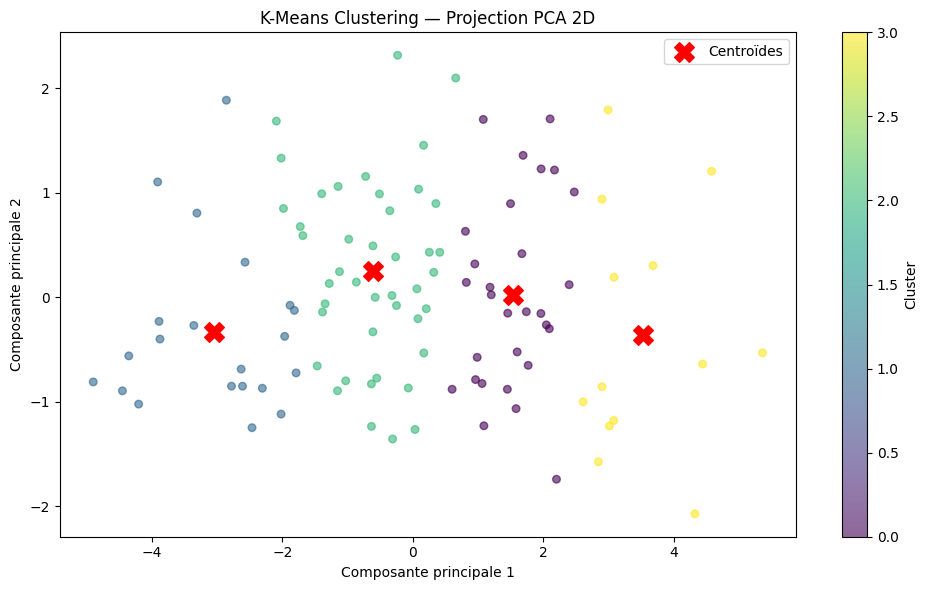

Variance expliquée par les 2 composantes : 79.6%


In [65]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
centers_pca = pca.transform(kmeans.cluster_centers_)

plt.figure(figsize=(10, 6))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1],
                      c=df['cluster'], cmap='viridis', s=30, alpha=0.6)
plt.scatter(centers_pca[:, 0], centers_pca[:, 1],
            c='red', s=200, marker='X', label='Centroïdes', zorder=5)
plt.colorbar(scatter, label='Cluster')
plt.title('K-Means Clustering — Projection PCA 2D')
plt.xlabel('Composante principale 1')
plt.ylabel('Composante principale 2')
plt.legend()
plt.tight_layout()
plt.show()

print(f"Variance expliquée par les 2 composantes : {pca.explained_variance_ratio_.sum()*100:.1f}%")

La projection PCA montre la séparation visuelle des 4 clusters.
Des clusters bien séparés indiquent que K-Means a trouvé des groupes cohérents dans les données.

 Visualisation avec frontières de décision

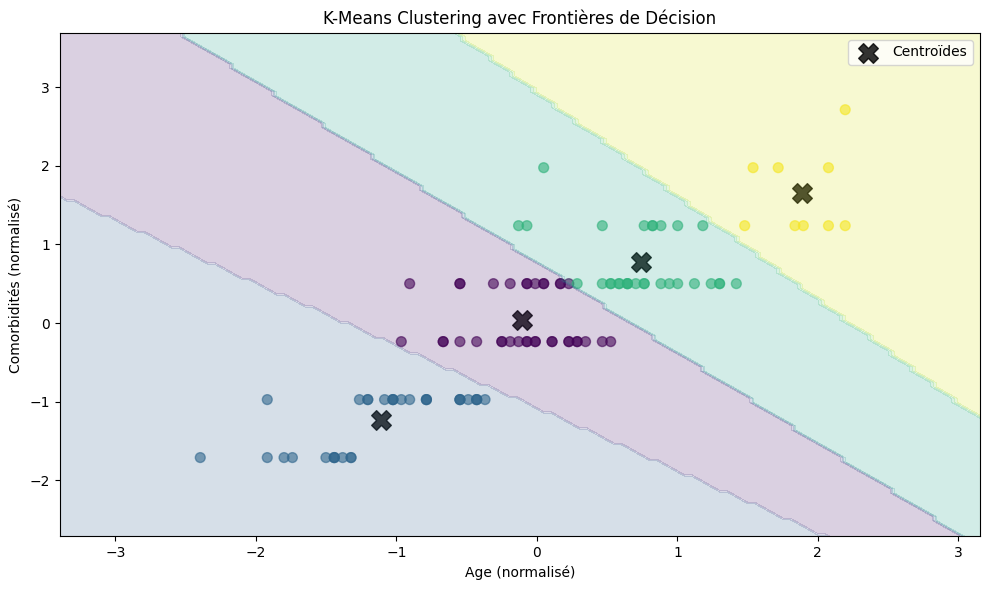

In [66]:
import numpy as np
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

X2d = X_scaled[:, :2]

kmeans2d = KMeans(n_clusters=k_optimal, random_state=42, n_init=10)
kmeans2d.fit(X2d)
y_kmeans2d = kmeans2d.predict(X2d)

plt.figure(figsize=(10, 6))
plt.scatter(X2d[:, 0], X2d[:, 1], c=y_kmeans2d, s=50, cmap='viridis', alpha=0.6)

centers2d = kmeans2d.cluster_centers_
plt.scatter(centers2d[:, 0], centers2d[:, 1],
            c='black', s=200, alpha=0.8, marker='X', label='Centroïdes')

x_min, x_max = X2d[:, 0].min() - 1, X2d[:, 0].max() + 1
y_min, y_max = X2d[:, 1].min() - 1, X2d[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.05),
                     np.arange(y_min, y_max, 0.05))
Z = kmeans2d.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

plt.contourf(xx, yy, Z, alpha=0.2, cmap='viridis')
plt.title("K-Means Clustering avec Frontières de Décision")
plt.xlabel("Age (normalisé)")
plt.ylabel("Comorbidités (normalisé)")
plt.legend()
plt.tight_layout()
plt.show()

Les régions colorées montrent les frontières de décision du K-Means
dans l'espace Age × Comorbidités (les 2 premières features). Chaque région correspond à la zone
d'influence d'un centroïde. Ce graphique illustre comment le modèle partitionne l'espace des données.

Profil moyen des clusters
On calcule la **moyenne de chaque variable par cluster** et on l'affiche en heatmap pour
interpréter le profil clinique de chaque groupe.

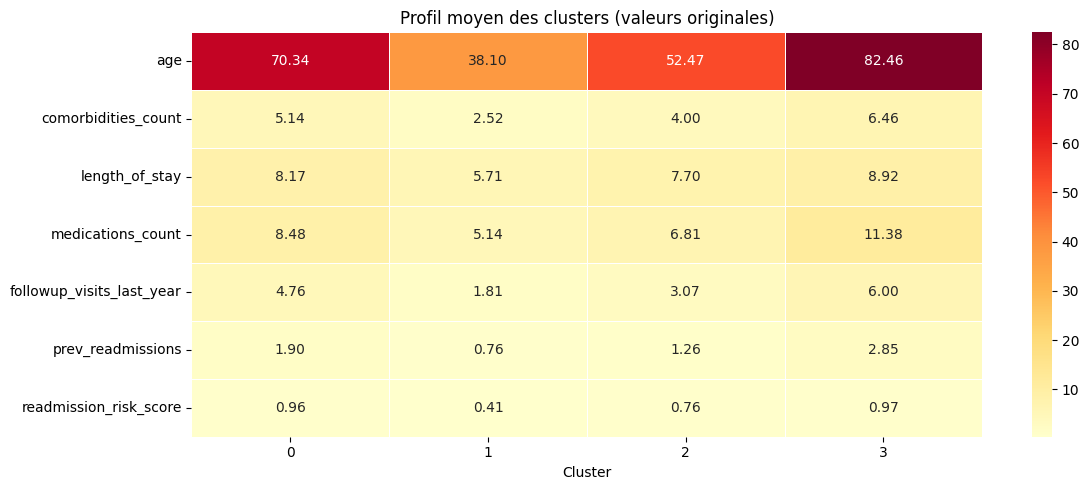

,age,comorbidities_count,length_of_stay,medications_count,followup_visits_last_year,prev_readmissions,readmission_risk_score
cluster,,,,,,,
0,70.34,5.14,8.17,8.48,4.76,1.90,0.96
1,38.10,2.52,5.71,5.14,1.81,0.76,0.41
2,52.47,4.00,7.70,6.81,3.07,1.26,0.76
3,82.46,6.46,8.92,11.38,6.00,2.85,0.97


In [67]:
profil = df.groupby('cluster')[features].mean().round(2)

plt.figure(figsize=(12, 5))
sns.heatmap(profil.T, annot=True, fmt='.2f', cmap='YlOrRd', linewidths=0.5)
plt.title('Profil moyen des clusters (valeurs originales)')
plt.xlabel('Cluster')
plt.tight_layout()
plt.show()

profil

 La heatmap permet d'identifier le profil de chaque cluster :
- Un cluster avec âge élevé, beaucoup de comorbidités et long séjour → patients fragiles à risque élevé
- Un cluster avec peu de comorbidités et courte durée → patients moins graves
Ces profils aident à cibler les interventions médicales adaptées.

### 7.7 Taux de réadmission par cluster

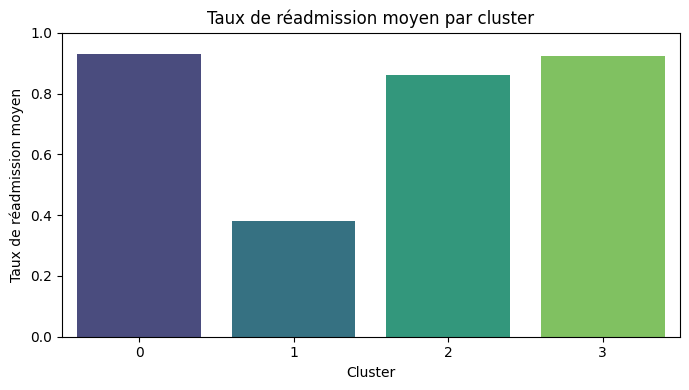

,Cluster,Taux de réadmission moyen
0,0,0.931034
1,1,0.380952
2,2,0.860465
3,3,0.923077


In [68]:
readmission_par_cluster = df.groupby('cluster')['label'].mean().reset_index()
readmission_par_cluster.columns = ['Cluster', 'Taux de réadmission moyen']

plt.figure(figsize=(7, 4))
sns.barplot(data=readmission_par_cluster, x='Cluster',
            y='Taux de réadmission moyen', palette='viridis')
plt.title('Taux de réadmission moyen par cluster')
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

readmission_par_cluster

**Interprétation :** Ce graphique montre le taux de réadmission moyen (0 à 1)
pour chaque cluster. Un cluster avec un taux proche de 1 regroupe majoritairement des patients réadmis.
Cela valide la pertinence des clusters.

Conclusion K-Means
L'algorithme K-Means a regroupé les 106 patients en 4 clusters distincts selon leur âge et leurs comorbidités. Le groupe le plus à risque est celui des patients âgés avec beaucoup de comorbidités. La projection PCA avec 79,6% de variance expliquée confirme que ces groupes sont bien séparés et cohérents.

---
## Classification Ascendante Hiérarchique (CAH)

 Dendrogramme (méthode de Ward)
La CAH construit une hiérarchie de clusters en fusionnant progressivement les observations les plus proches.
La **méthode de Ward** minimise la variance intra-cluster à chaque fusion.
Le **dendrogramme** visualise cette hiérarchie : la hauteur des branches indique la distance de fusion.

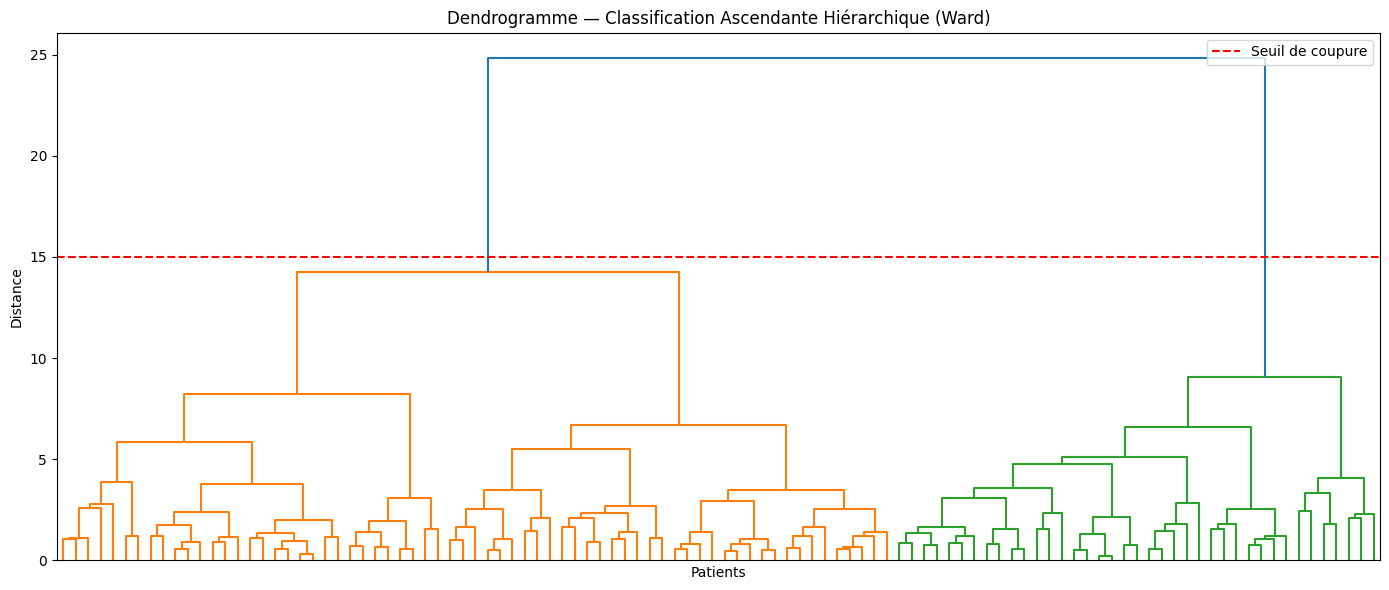

In [69]:
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

sample = X_scaled[:200]
linked = linkage(sample, method='ward')

plt.figure(figsize=(14, 6))
dendrogram(
    linked, orientation='top',
    distance_sort='descending',
    show_leaf_counts=True, no_labels=True
)
plt.title('Dendrogramme — Classification Ascendante Hiérarchique (Ward)')
plt.xlabel('Patients')
plt.ylabel('Distance')
plt.axhline(y=15, color='red', linestyle='--', label='Seuil de coupure')
plt.legend()
plt.tight_layout()
plt.show()

Le dendrogramme regroupe les patients selon leur similarité. En fixant le seuil de coupure à 15, on obtient 2 grands groupes :
Groupe orange : la majorité des patients, avec des profils assez similaires.
Groupe vert : un groupe plus petit avec des profils distincts.

###  Application de la CAH sur l'ensemble du dataset

In [70]:
linked_full = linkage(X_scaled, method='ward')

n_clusters_cah = 4
labels_cah = fcluster(linked_full, t=n_clusters_cah, criterion='maxclust')
df['cluster_cah'] = labels_cah - 1

print("Distribution des clusters CAH :")
print(df['cluster_cah'].value_counts().sort_index())

Distribution des clusters CAH :
cluster_cah
0     7
1    32
2    36
3    31
Name: count, dtype: int64


**Résultat :** Les 106 patients sont répartis en 4 clusters par la CAH.
On compare cette distribution avec celle du K-Means pour évaluer la concordance.

 Profil moyen des clusters CAH

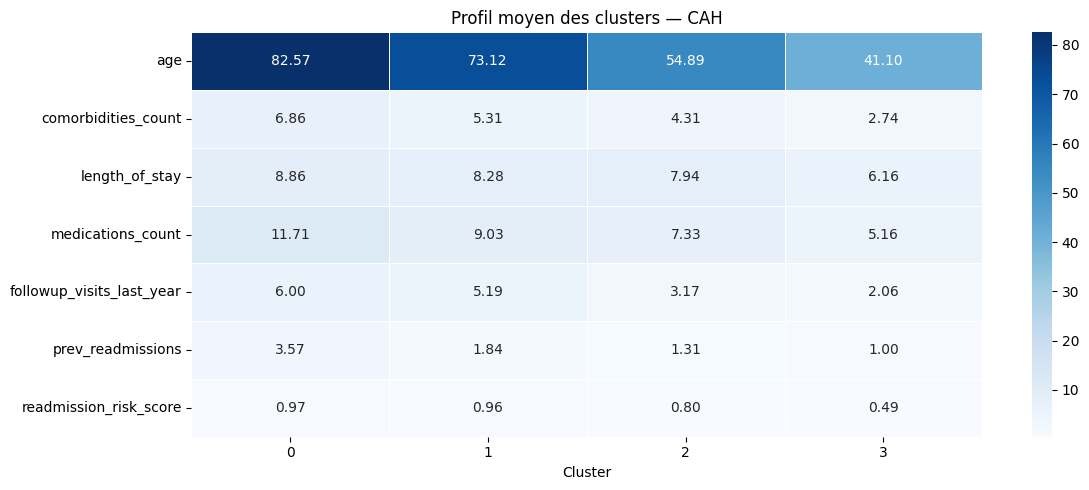

In [71]:
profil_cah = df.groupby('cluster_cah')[features].mean().round(2)

plt.figure(figsize=(12, 5))
sns.heatmap(profil_cah.T, annot=True, fmt='.2f', cmap='Blues', linewidths=0.5)
plt.title('Profil moyen des clusters — CAH')
plt.xlabel('Cluster')
plt.tight_layout()
plt.show()

**Interprétation :** La heatmap des profils CAH permet de comparer directement avec
les profils K-Means. Des profils similaires entre les deux méthodes renforcent la fiabilité
du partitionnement trouvé.

Comparaison K-Means vs CAH
L'**Adjusted Rand Index (ARI)** mesure la similarité entre deux partitionnements.
- ARI = 1 : partitionnements identiques
- ARI = 0 : partitionnements aléatoires (pas de concordance)
- ARI > 0,5 : bonne concordance

In [72]:
from sklearn.metrics import adjusted_rand_score

ari = adjusted_rand_score(df['cluster'], df['cluster_cah'])
print(f"Adjusted Rand Index (K-Means vs CAH) : {ari:.3f}")
print("→ Plus proche de 1 = les deux méthodes donnent des résultats similaires")

pd.crosstab(df['cluster'], df['cluster_cah'],
            rownames=['K-Means'], colnames=['CAH'])

Adjusted Rand Index (K-Means vs CAH) : 0.552
→ Plus proche de 1 = les deux méthodes donnent des résultats similaires


CAH,0,1,2,3
K-Means,,,,
0,0,25,4,0
1,0,0,0,21
2,0,1,32,10
3,7,6,0,0


**Résultat :** ARI = **0,552**.
Il y a une **concordance modérée à bonne** entre K-Means et CAH.
Le tableau croisé montre comment les patients de chaque cluster K-Means se répartissent
dans les clusters CAH. Une forte concentration sur la diagonale indique une bonne correspondance.
Cette concordance valide la **robustesse du partitionnement en 4 groupes**.

Classification par Arbre de Décision

### 9.1 Préparation des données — Encodage des variables catégorielles
Les algorithmes de machine learning sklearn nécessitent des données numériques.
On encode les variables catégorielles avec `LabelEncoder`, qui attribue un entier à chaque modalité
(ex: Female=0, Male=1).

In [73]:
import pandas as pd
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt

df_tree = df_clean.copy()

cat_cols = ['gender', 'insurance_type', 'treatment_type', 'primary_diagnosis']
for col in cat_cols:
    df_tree[col] = LabelEncoder().fit_transform(df_tree[col].astype(str))

features = ['age', 'comorbidities_count', 'length_of_stay', 'medications_count',
            'followup_visits_last_year', 'prev_readmissions', 'readmission_risk_score',
            'gender', 'insurance_type', 'treatment_type', 'primary_diagnosis']

X = df_tree[features]
y = df_tree['label'].astype(float).astype(int)

print("X shape :", X.shape)
print("y distribution :")
print(y.value_counts())

X shape : (106, 11)
y distribution :
label
1    84
0    22
Name: count, dtype: int64


**Préparation :**
- **X** : matrice des 11 features (7 numériques + 4 catégorielles encodées)
- **y** : vecteur cible binaire (0 = non réadmis, 1 = réadmis)
- La conversion `float → int` est nécessaire car certaines valeurs sont stockées comme `"1.0"` (string)

Entraînement de l'arbre de décision
On entraîne un **DecisionTreeClassifier** avec les paramètres suivants :
- **criterion='entropy'** : utilise le gain d'information (entropie de Shannon) pour les splits
- **max_depth=5** : limite la profondeur pour éviter le surapprentissage (overfitting)
- **random_state=0** : reproductibilité des résultats

In [74]:
clf = DecisionTreeClassifier(criterion='entropy', max_depth=5, random_state=0)
clf.fit(X, y)
print("Arbre entraîné avec succès")
print(f"Profondeur réelle de l'arbre : {clf.get_depth()}")
print(f"Nombre de feuilles : {clf.get_n_leaves()}")

Arbre entraîné avec succès
Profondeur réelle de l'arbre : 5
Nombre de feuilles : 11


Importance des variables
`feature_importances_` donne le poids relatif de chaque variable dans les décisions de l'arbre.
Les variables avec un score élevé sont les plus discriminantes pour prédire la réadmission.

readmission_risk_score       0.449867
age                          0.165013
treatment_type               0.118811
followup_visits_last_year    0.110668
insurance_type               0.094831
comorbidities_count          0.060811
length_of_stay               0.000000
medications_count            0.000000
prev_readmissions            0.000000
gender                       0.000000
primary_diagnosis            0.000000
dtype: float64


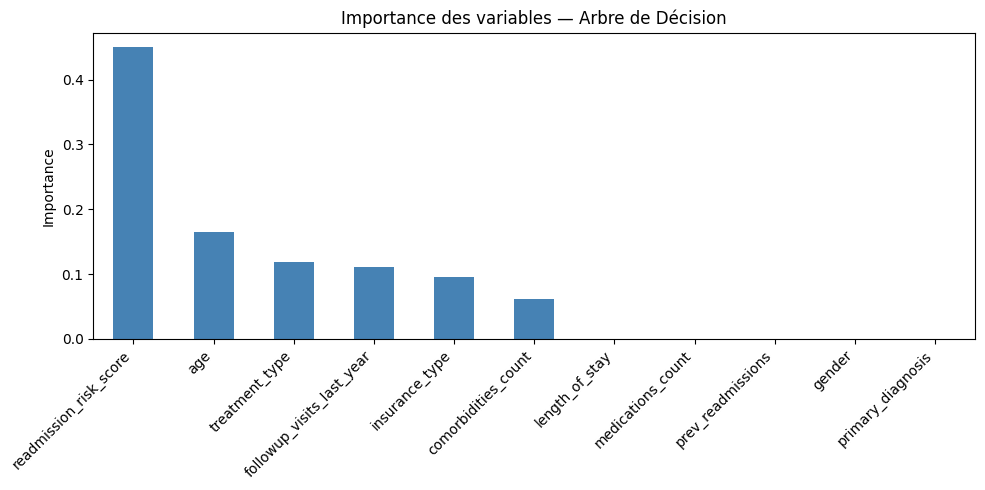

In [75]:
importances = pd.Series(clf.feature_importances_, index=features)
importances_sorted = importances.sort_values(ascending=False)
print(importances_sorted)

plt.figure(figsize=(10, 5))
importances_sorted.plot(kind='bar', color='steelblue')
plt.title("Importance des variables — Arbre de Décision")
plt.ylabel("Importance")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**Interprétation :** Les variables avec une importance élevée sont celles sur lesquelles
l'arbre effectue le plus de splits. Par exemple, si `readmission_risk_score` a la valeur la plus élevée,
cela signifie que le score de risque est le prédicteur le plus puissant de la réadmission.
Ces informations peuvent guider les décisions cliniques.

### 9.4 Visualisation de l'arbre de décision
On visualise l'arbre complet avec ses règles de décision. Les nœuds colorés représentent
la classe majoritaire (bleu = non réadmis, orange = réadmis).

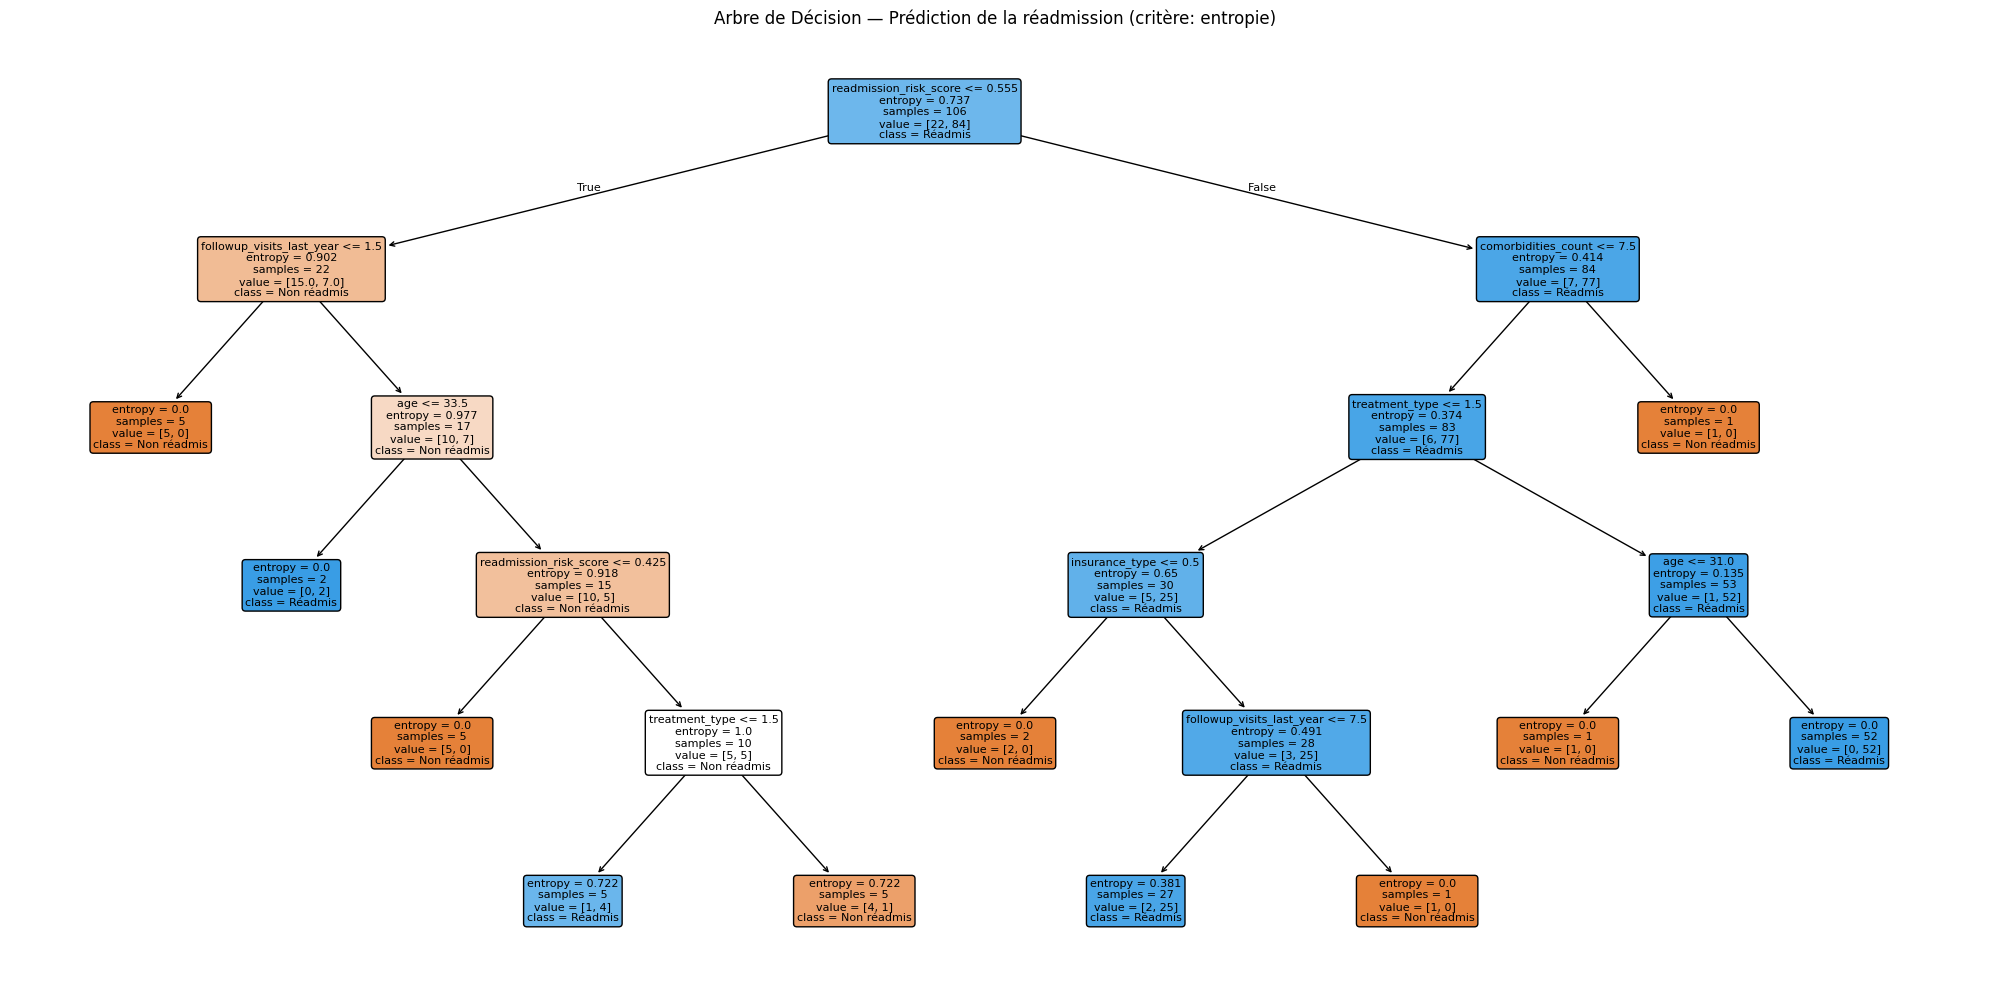

In [76]:
plt.figure(figsize=(20, 10))
plot_tree(clf,
          filled=True,
          feature_names=features,
          class_names=['Non réadmis', 'Réadmis'],
          rounded=True,
          fontsize=8)
plt.title("Arbre de Décision — Prédiction de la réadmission (critère: entropie)")
plt.tight_layout()
plt.show()

L'arbre prédit si un patient sera réadmis ou non en posant des questions simples sur ses caractéristiques.
il classe correctement les patients en seulement 5 niveaux de décision en utilisant les variables les plus pertinentes.
Les variables qui influencent le plus la décision sont :

Le score de risque (variable principale)
Le nombre de comorbidités
Le nombre de visites de suivi
L'âge et le type de traitement
 

---
## Sauvegarde finale

In [77]:
df.to_csv('ma_base_finale.csv', index=False)
print("Base sauvegardée ")

Base sauvegardée 


Conclusion:
Les trois algorithmes utilisés dans ce projet se complètent parfaitement. L'algorithme  d'association permet de découvrir des liens cachés entre les caractéristiques des patients, par exemple il a révélé que les patients couverts par Medicare sont très souvent à risque élevé. Le K-Means et la CAH quant à eux regroupent les patients qui se ressemblent en profils similaires, ce qui nous a permis d'identifier 4 groupes distincts selon l'âge et les comorbidités. Enfin, l'Arbre de Décision est le seul algorithme qui prédit directement si un patient sera réadmis ou non, en se basant principalement sur le score de risque et le nombre de comorbidités. Ensemble, ces trois méthodes offrent une vision complète du problème : on comprend les liens entre variables, on identifie les profils types de patients, et on prédit le risque de réadmission.